# Coordination de satellites

### Etudiants :
- Jawher JRIBY 3702809
- Mélanie DELLUC 21104033

## 1 - Introduction

L'objectif de ce projet est d'étudier un problème d'allocation multi-agents de tâches dans lequel des tâches d’observations doivent être allouées à des constellations de satellites en orbite autour de la Terre.

...

## 2 - Préparation : Instances et planification des tâches

In [637]:
from typing import Callable, List, Set, Tuple, Dict
import random
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np

### 2.1 - Générateur aléatoire

Dans un premier temps, nous allons implémenter un générateur aléatoire d'instances du problème EOSCSP à partir d'un nombre de satellites, d'utilisateurs exclusifs et de tâches. Pour cela, nous devons établir les structures de données nécessaires à la représentation du problème (EOSCSP, satellites, utilisateurs, requêtes, observations, solutions) et leurs contraintes associées avant de générer des instances de chaque élément. 

Nous avons commencé par créer des instances aléatoires générales, donc sans se préoccuper de l'exclusivité. Puis, nous y avons ajouté les contraintes supplémentaires liées au problème d'exclusivité (section 2.1.5). 

#### 2.1.1 - Structures de données

Pour représenter nos satellites, nos utilisateurs, nos observations, etc, nous avons implémenté diverses structures de données basées sur l'article :
- EOSCSP : Le problème de planification de constellation de satellites d'observation de la Terre avec exclusivités (ou EOSCSP) est défini par un tuple 𝑃 = ⟨S,U,R,O⟩, tel que S est un ensemble de satellites, U est un ensemble d'utilisateurs, R est un ensemble de requêtes, et O est un ensemble d'observations à planifier pour satisfaire les requêtes de R.
- 

In [638]:
class EOSCSP :
    def __init__(self, eoscsp_id : int, S : Set['Satellite'], U : Set['User'], R : Set['Request'], O : Set['Observation']):
        self.eoscsp_id = eoscsp_id
        self.S = S
        self.U = U 
        self.R = R
        self.O = O

In [639]:
class Satellite :
    def __init__(self, s_id : int, t_start: float, t_end: float, kappa: int, tau: Callable[['Observation', 'Observation'], float]):
        self.s_id = s_id
        self.t_start = t_start
        self.t_end = t_end
        self.kappa = kappa
        self.tau = tau

In [640]:
class User :
    def __init__(self, u_id : int, e : Set[Tuple['Satellite', float, float]], p : int):
        self.u_id = u_id
        self.e = e
        self.p = p

In [641]:
class Request :
    def __init__(self, r_id : int, t_start : float, t_end : float, duration : float, reward : float, p : Tuple[float, float, float], u : User, thetas : List['Observation']):
        self.r_id = r_id
        self.t_start = t_start
        self.t_end = t_end
        self.duration = duration
        self.reward = reward
        self.p = p
        self.u = u
        self.thetas = thetas

In [642]:
class Observation :
    def __init__(self, o_id : int, t_start : float, t_end : float, duration : float, r : 'Request', reward : float, s : 'Satellite', u : 'User', p : int):
        self.o_id = o_id
        self.t_start = t_start 
        self.t_end = t_end
        self.duration = duration
        self.r = r
        self.reward = reward
        self.s = s
        self.u = u
        self.p = p

In [643]:
class Solution :
    def __init__(self, sol_id : int, M : Dict['Observation', float]):
        self.sol_id = sol_id
        self.M = M 

## 2.1.2 - Contraintes générales sur les données

Dans cette partie, nous avons créé les contraintes générales, à la création des instances, ainsi que quelques fonctions utiles telles que overlap pour éviter les chevauchements, et tau pour la fonction de transition entre deux observations.

Nous créons des satellites ayant une date limite de fin supérieure à sa date de début, et ayant une capacité d'au moins un.
Pour les utilisateurs classiques, nous nous assurons qu'ils aient au moins un de priorité.
On s'assure aussi de générer des requêtes avec une date de fin supérieure à sa date de début, une durée positive ou égale à 0, et une récompense positive.

In [644]:
def overlap(a_start, a_end, b_start, b_end, eps=1e-9):
    return (a_start < b_end - eps) and (b_start < a_end - eps)

In [645]:
def constraints_EOSCSP():
    return

In [776]:
def constraints_satellites(s):
    errors = []

    if s.t_start >= s.t_end :
        errors.append("Sattelite s : invalid time -> start > end")

    if s.kappa < 1 :
        errors.append("Sattelite s : invalid capacity -> kappa < 1")

    return errors

In [777]:
def constraints_users(u):
    errors = []

    if u.p < 1 :
        errors.append("User u : invalid priority -> p < 1")
    
    return errors

In [794]:
def constraints_requests(r):
    errors = []

    if r.t_start >= r.t_end :
        errors.append("Request r : invalid time -> start > end")

    if r.duration <= 0 :
        errors.append("Request r : invalid duration -> duration <= 0")

    if r.reward < 0 :
        errors.append("Request r : invalid reward -> reward < 0")
                
    return errors

In [779]:
def constraints_observations(o, requests, satellites, ex_by_sat=None, eps=1e-9):
    errors = []

    if o.t_start >= o.t_end :
        errors.append("Observation o : invalid time -> start > end")

    if o.r not in requests:
        errors.append("Observation o : unknown request")

    if o.s not in satellites:
        errors.append("Observation o : unknown satellite")

    if not (o.s.t_start <= o.t_start < o.t_end <= o.s.t_end):
        errors.append("Observation o: outside satellite horizon")
        
    # pas de chevauchement partiel avec une exclusive
    if ex_by_sat is not None:
        for (xs, xe) in ex_by_sat.get(o.s.s_id, []):
            if overlap(xs, xe, o.t_start, o.t_end, eps):
                if not (o.t_start + eps >= xs and o.t_end <= xe + eps):
                    errors.append("Observation: partial overlap with exclusive")
                    break

    return errors

In [780]:
def constraints_solutions():
    return

In [781]:
def constraints_exclusifs_users(u, satellites, users_exclusifs):
    errors = []

    for (s, start, end) in getattr(u, "e", []) or []:
        if s not in satellites:
            errors.append("Exclusive: unknown satellite")
        elif not (s.t_start <= start < end <= s.t_end):
            errors.append("Exclusive: outside satellite horizon")

    # un seul user exclusif par satellite
    sats_u = {s.s_id for (s, _, _) in getattr(u, "e", []) or []}
    for ue in users_exclusifs:
        if ue is u:
            continue
        sats_ue = {s.s_id for (s, _, _) in getattr(ue, "e", []) or []}
        if sats_u.intersection(sats_ue):
            errors.append("Only one exclusive user allowed per satellite")

    return errors


In [782]:
def tau(o,p):
    return 1.0

#### 2.1.3 - Construction d'instances des données (hors exclusivité)

In [783]:
def generate_satellites(nb_satellites, horizon, kappa_min, kappa_max, max_tries=10000):
    S = set()
    
    for i in range(nb_satellites) :
        for j in range(max_tries):
            start = 0
            end = start + horizon
            kappa = random.randint(kappa_min, kappa_max)
            s = Satellite(s_id=i, t_start=start,t_end=end,kappa=kappa,tau=None)
            if constraints_satellites(s) == [] :
                S.add(s)
                break
    return S

In [784]:
def generate_users(nb_users, min_priority=1, max_priority=10, fixed_priority=None, max_tries=10000):
    U = set()

    for i in range(nb_users):
        for j in range(max_tries):
            p = fixed_priority if fixed_priority is not None else random.randint(min_priority, max_priority)
            u = User(u_id=i, e=set(), p=p,)

            if constraints_users(u) == [] :
                U.add(u)
                break
    return U


In [785]:
def generate_requests(users, nb_requests_per_user, horizon,
                      d_min, d_max, r_min, r_max):
    R = set()
    r_id = 0

    for u in users:
        for i in range(nb_requests_per_user):
            d = random.uniform(d_min, d_max)
            start = random.uniform(0.0, horizon - d)
            end = start + d
            reward = random.uniform(r_min, r_max)

            p = [random.uniform(-1, 1) for _ in range(3)]

            r = Request(
                r_id=r_id,
                t_start=start,
                t_end=end,
                duration=d,
                reward=reward,
                p=p,
                u=u,
                thetas=[]
            )
            r.r_local = i

            if constraints_requests(r) == []:
                R.add(r)
                r_id += 1

    return R


In [786]:
def build_exclusive_index(users):
    ex_by_sat = {}
    for u in users:
        for (s, xs, xe) in getattr(u, "e", []) or []:
            ex_by_sat.setdefault(s.s_id, []).append((xs, xe))
    return ex_by_sat

In [787]:
def generate_observations(satellites, users, requests,
                          opp_per_request,
                          obs_window_min, obs_window_max,
                          opp_duration=5.0,
                          max_tries=10000):
    O = set()
    ex_by_sat = build_exclusive_index(users)
    o_id = 0

    for r in requests:
        for i in range(opp_per_request):
            for _ in range(max_tries):
                s = random.choice(list(satellites))
                d = opp_duration

                start_min = r.t_start
                start_max = r.t_end - d
                if start_max < start_min:
                    continue

                inside = random.random() < 0.5
                placed = False

                if inside and s.s_id in ex_by_sat:
                    xs, xe = random.choice(ex_by_sat[s.s_id])
                    if xe - xs >= d:
                        o_start = random.uniform(xs, xe - d)
                        o_end = o_start + d
                        placed = True
                else:
                    o_start = random.uniform(start_min, start_max)
                    o_end = o_start + d
                    placed = True

                if not placed:
                    continue

                o = Observation(
                    o_id=o_id,
                    r=r,
                    u=r.u,
                    s=s,
                    t_start=o_start,
                    t_end=o_end,
                    duration=d,
                    reward=r.reward,
                    p=r.u.p
                )
                o.o_local = i
                o.r_local = r.r_local

                if constraints_observations(o, requests, satellites, ex_by_sat) == []:
                    O.add(o)
                    r.thetas.append(o_id)
                    o_id += 1
                    break

    return O


In [788]:
def generate_EOSCSP(i, satellites, users, requests, observations):
    return EOSCSP(eoscsp_id=i, S=satellites, U=users, R=requests, O=observations)

In [789]:
def generate_users_exclusifs(k, satellites, nb_users,
                            min_priority=1, max_priority=10,
                            k_excl_per_user=3,
                            e_dur_min=15, e_dur_max=20,
                            max_tries=10000):
    U = set()

    sats = list(satellites)
    random.shuffle(sats)
    nb_users = min(nb_users, len(sats))

    for i in range(nb_users):
        s = sats[i]                      # satellite fixe
        p = random.randint(min_priority, max_priority)
        res = set()

        for _ in range(k_excl_per_user):
            dur = random.uniform(e_dur_min, e_dur_max)
            dur = min(dur, 0.5 * (s.t_end - s.t_start))

            placed = False
            for _try in range(max_tries):
                start = random.uniform(s.t_start, s.t_end - dur)
                end = start + dur
                if all(end <= st or start >= en for (_, st, en) in res):
                    res.add((s, start, end))
                    placed = True
                    break

            if not placed:
                res = None
                break

        if res is None:
            continue

        u = User(u_id=i + k, e=res, p=p)

        if constraints_users(u) == [] and constraints_exclusifs_users(u, satellites, U) == []:
            U.add(u)

    return U


#### Fonctions d'affichage

In [790]:
from matplotlib.patches import Rectangle
from collections import defaultdict
import matplotlib.pyplot as plt

def assign_lanes(intervals):
    intervals = sorted(intervals, key=lambda x: (x["start"], x["end"]))
    lane_ends = []
    for it in intervals:
        placed = False
        for lane, last_end in enumerate(lane_ends):
            if it["start"] >= last_end:
                it["lane"] = lane
                lane_ends[lane] = it["end"]
                placed = True
                break
        if not placed:
            it["lane"] = len(lane_ends)
            lane_ends.append(it["end"])
    return intervals, len(lane_ends)


def plot_eoscsp_windows(
    EOSCSP,
    plan=None,
    title="EOSCSP",
    show_labels=True,
    show_exclusives=True,
    show_plan_labels=True,
):
    satellites = EOSCSP.S
    observations = EOSCSP.O
    users = EOSCSP.U

    # --- Satellite order ---
    sat_ids = []
    for idx, s in enumerate(satellites):
        sid = getattr(s, "s_id", idx)
        sat_ids.append(sid)
    sat_ids_sorted = sorted(sat_ids)

    # --- User ids present ---
    user_ids = sorted({getattr(o.u, "u_id", 0) for o in observations})
    if plan is not None:
        user_ids = sorted(set(user_ids) | {getattr(obs.u, "u_id", 0) for obs, _, _ in plan})
    if users is not None:
        user_ids = sorted({u.u_id for u in users} | set(user_ids))

    # --- Colors ---
    cmap = plt.get_cmap("tab10")
    user_color = {uid: cmap(i % 10) for i, uid in enumerate(user_ids)}

    fig, ax = plt.subplots(figsize=(12, 7))

    # Layout parameters
    row_height = 0.8
    y_gap = 0.35

    # --- Time bounds ---
    all_starts = [o.t_start for o in observations]
    all_ends = [o.t_end for o in observations]

    if show_exclusives and users is not None:
        for u in users:
            for ew in getattr(u, "e_u", []):
                all_starts.append(ew.t_start)
                all_ends.append(ew.t_end)

    if plan is not None:
        for obs, start, end in plan:
            all_starts.append(start)
            all_ends.append(end)

    t_min = min(all_starts) if all_starts else 0.0
    t_max = max(all_ends) if all_ends else 1.0

    # Helpers
    def y_of_sat_id(sid):
        return sat_ids_sorted.index(sid) * (row_height + y_gap)

    def sid_of_sat(s_obj):
        return getattr(s_obj, "s_id", None)

    # -------------------------
    # 1) Draw exclusive windows (background, hatched)
    # -------------------------
    if show_exclusives and users is not None:
        for u in users:
            uid = getattr(u, "u_id", 0)
            for ew in getattr(u, "e", []):
                sid = sid_of_sat(ew[0])
                if sid is None or sid not in sat_ids_sorted:
                    continue

                y = y_of_sat_id(sid)
                x = ew[1]
                w = ew[2] - ew[1]
                if w <= 0:
                    continue

                hatched = Rectangle(
                    (x, y),
                    w,
                    row_height,
                    facecolor=user_color.get(uid, cmap(0)),
                    edgecolor=user_color.get(uid, cmap(0)),
                    linewidth=1.0,
                    alpha=0.18,
                    hatch="///",
                    zorder=0,
                )
                ax.add_patch(hatched)

    # -------------------------
    # 2) Draw observation windows (transparent) - STACKED LANES
    # -------------------------
    obs_by_sat = defaultdict(list)

    for o in observations:
        uid = getattr(o.u, "u_id", 0)
        sid = sid_of_sat(o.s)
        if sid is None or sid not in sat_ids_sorted:
            continue

        start = o.t_start
        end = o.t_end
        if end - start <= 0:
            continue

        oid = getattr(o, "o_id", None)

        uid = getattr(o.u, "u_id", 0)
        r_local = getattr(getattr(o, "r", None), "r_local", None)
        o_local = getattr(o, "o_local", None)
        label = f"o{uid},{r_local},{o_local}"

        obs_by_sat[sid].append({
            "start": start,
            "end": end,
            "uid": uid,
            "label": label,
            "oid": oid,  # <-- keep oid so we can reuse the SAME lane for the plan
        })

    # Band for observation windows (unchanged)
    obs_band_height = 0.30
    obs_band_y0 = (row_height - obs_band_height) / 2
    obs_band_y0 += 0.18

    # Map (sid, oid) -> (lane, n_lanes) to reuse for the plan
    obs_lane = {}

    for sid, intervals in obs_by_sat.items():
        intervals, n_lanes = assign_lanes(intervals)

        lane_h = obs_band_height / max(1, n_lanes)
        rect_h = lane_h * 0.85
        y_base = y_of_sat_id(sid)

        for it in intervals:
            start, end = it["start"], it["end"]
            w = end - start
            uid = it["uid"]

            y0 = (
                y_base
                + obs_band_y0
                + it["lane"] * lane_h
                + (lane_h - rect_h) / 2
            )

            # store lane for THIS observation window
            if it.get("oid", None) is not None:
                obs_lane[(sid, it["oid"])] = (it["lane"], n_lanes)

            rect = Rectangle(
                (start, y0),
                w,
                rect_h,
                facecolor=user_color.get(uid, cmap(0)),
                edgecolor="black",
                linewidth=1,
                alpha=0.25,
                zorder=2,
            )
            ax.add_patch(rect)

            if show_labels:
                ax.text(
                    start + w / 2,
                    y0 + rect_h / 2,
                    it["label"],
                    ha="center",
                    va="center",
                    fontsize=8,
                    alpha=0.9,
                    zorder=3,
                )

    # -------------------------
    # 3) Draw plan INSIDE the SAME lane as its observation window
    # -------------------------
    if plan is not None:
        for obs, start, end in plan:
            uid = getattr(obs.u, "u_id", 0)
            sid = sid_of_sat(obs.s)
            if sid is None or sid not in sat_ids_sorted:
                continue
            if end - start <= 0:
                continue

            oid = getattr(obs, "o_id", None)
            y_base = y_of_sat_id(sid)

            # default fallback: draw in the center of the obs band
            n_lanes = 1
            lane_idx = 0

            if oid is not None and (sid, oid) in obs_lane:
                lane_idx, n_lanes = obs_lane[(sid, oid)]

            lane_h = obs_band_height / max(1, n_lanes)
            rect_h = lane_h * 0.85

            # EXACT same y computation as the window lane
            y0 = (
                y_base
                + obs_band_y0
                + lane_idx * lane_h
                + (lane_h - rect_h) / 2
            )

            exec_rect = Rectangle(
                (start, y0),
                end - start,
                rect_h,
                facecolor=user_color.get(uid, cmap(0)),
                edgecolor="black",
                linewidth=2.0,
                alpha=0.90,
                zorder=7,  # above windows
            )
            ax.add_patch(exec_rect)

            if show_plan_labels:
                uid = getattr(obs.u, "u_id", 0)
                r_local = getattr(getattr(obs, "r", None), "r_local", None)
                o_local = getattr(obs, "o_local", None)
                label = f"o{uid},{r_local},{o_local}"
                ax.text(
                    start + (end - start) / 2,
                    y0 + rect_h / 2,
                    label,
                    ha="center",
                    va="center",
                    fontsize=9,
                    alpha=0.95,
                    zorder=8,
                )

    # --- Y axis labels ---
    y_ticks = []
    y_labels = []
    for sid in sat_ids_sorted:
        y_ticks.append(y_of_sat_id(sid) + row_height / 2)
        y_labels.append(f"S{sid}")
    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_labels)

    # --- X axis ---
    ax.set_xlim(t_min - 0.5, t_max + 0.5)
    ax.set_xlabel("time")
    ax.set_ylabel("satellite")
    ax.set_title(title)

    # --- Fix Y limits ---
    if sat_ids_sorted:
        y0 = y_of_sat_id(sat_ids_sorted[0])
        y_last = y_of_sat_id(sat_ids_sorted[-1])
        ax.set_ylim(y0 - 0.2, y_last + row_height + 0.2)

    # --- Legend ---
    handles = []
    labels = []
    for uid in user_ids:
        patch = Rectangle((0, 0), 1, 1, facecolor=user_color[uid], edgecolor="black", alpha=0.25)
        handles.append(patch)
        labels.append(f"u{uid}")
    ax.legend(handles, labels, loc="upper right")

    ax.grid(True, axis="x", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

In [791]:
def format_eoscsp(P, max_items=30) -> str:
    """
    P: instance of EOSCSP
    max_items: limit printed items per section to keep it readable
    """

    def sid(s): return getattr(s, "s_id", "?")
    def uid(u): return getattr(u, "u_id", "?")
    def rid(r): return getattr(r, "r_id", "?")
    def oid(o): return getattr(o, "o_id", "?")

    lines = []
    lines.append(f"EOSCSP instance #{P.eoscsp_id}")
    lines.append(f"|S|={len(P.S)} |U|={len(P.U)} |R|={len(P.R)} |O|={len(P.O)}")
    lines.append("")

    # --- Satellites ---
    lines.append("Satellites:")
    for i, s in enumerate(sorted(P.S, key=lambda x: getattr(x, "s_id", 0))):
        if i >= max_items:
            lines.append(f"  ... ({len(P.S)-max_items} more)")
            break
        lines.append(
            f"  S{sid(s)}: horizon=[{s.t_start:.2f},{s.t_end:.2f}] kappa={getattr(s,'kappa','?')}"
        )
    lines.append("")

    # --- Users + exclusives ---
    lines.append("Users:")
    for i, u in enumerate(sorted(P.U, key=lambda x: getattr(x, "u_id", 0))):
        if i >= max_items:
            lines.append(f"  ... ({len(P.U)-max_items} more)")
            break

        e = getattr(u, "e", set())
        lines.append(f"  u{uid(u)}: priority={getattr(u,'p','?')} exclusives={len(e)}")
        # print exclusives
        for j, (s, a, b) in enumerate(sorted(list(e), key=lambda t: (sid(t[0]), t[1]))):
            if j >= 10:
                lines.append("    ...")
                break
            lines.append(f"    - (S{sid(s)}, [{a:.2f},{b:.2f}])")
    lines.append("")

    # --- Requests ---
    lines.append("Requests:")
    for i, r in enumerate(sorted(P.R, key=lambda x: getattr(x, "r_id", 0))):
        if i >= max_items:
            lines.append(f"  ... ({len(P.R)-max_items} more)")
            break
        u = getattr(r, "u", None)
        lines.append(
            f"  r{rid(r)}: user=u{uid(u) if u else '?'} "
            f"duration={getattr(r,'duration','?')} reward={getattr(r,'reward','?')}"
        )
    lines.append("")

    # --- Observations ---
    lines.append("Observations (windows):")
    obs_sorted = sorted(P.O, key=lambda o: (getattr(o.s, "s_id", 0), o.t_start, oid(o)))
    for i, o in enumerate(obs_sorted):
        if i >= max_items:
            lines.append(f"  ... ({len(P.O)-max_items} more)")
            break
        lines.append(
            f"  o{oid(o)}: u{uid(o.u)} on S{sid(o.s)} "
            f"window=[{o.t_start:.2f},{o.t_end:.2f}] "
            f"dur={o.duration:.2f} reward={o.reward:.2f} "
            f"(r{rid(o.r)})"
        )

    return "\n".join(lines)


In [792]:
def format_solution(sol, title=None) -> str:
    """
    sol: instance of Solution with sol.M: dict[Observation, float]
    """
    def sid(s): return getattr(s, "s_id", "?")
    def uid(u): return getattr(u, "u_id", "?")
    def oid(o): return getattr(o, "o_id", "?")
    def rid(r): return getattr(r, "r_id", "?")

    lines = []
    lines.append(title if title else f"Solution #{sol.sol_id}")
    lines.append(f"Planned observations: {len(sol.M)}")
    lines.append("")

    # Compute total reward
    total_reward = sum(getattr(o, "reward", 0.0) for o in sol.M.keys())
    lines.append(f"Total reward (sum of planned observations): {total_reward:.2f}")
    lines.append("")

    # Sort by satellite then start time
    items = []
    for o, start in sol.M.items():
        end = start + getattr(o, "duration", 0.0)
        items.append((getattr(o.s, "s_id", 0), start, end, o))
    items.sort(key=lambda x: (x[0], x[1]))

    current_sid = None
    for s_id, start, end, o in items:
        if current_sid != s_id:
            current_sid = s_id
            lines.append(f"Satellite S{s_id}:")
        lines.append(
            f"  o{oid(o)} (r{rid(o.r)} u{uid(o.u)}): "
            f"start={start:.2f} end={end:.2f} "
            f"dur={o.duration:.2f} reward={o.reward:.2f}"
        )

    return "\n".join(lines)

#### 2.1.4 - Tests sur des instances sans exclusivité

In [731]:
horizon = 300.0

satellites = generate_satellites(3, horizon, 100, 200)
users = generate_users(3)
requests = generate_requests(users, 3, horizon, 5.0, 10.0, 5.0, 50.0)
observations = generate_observations(satellites, users, requests, 3, 10.0, 150.0)

eoscsp_1 = generate_EOSCSP(0, satellites, users, requests, observations)

print(f"Generated: |S|={len(satellites)} |U|={len(users)} |R|={len(requests)} |O|={len(observations)}")

Generated: |S|=3 |U|=3 |R|=9 |O|=27


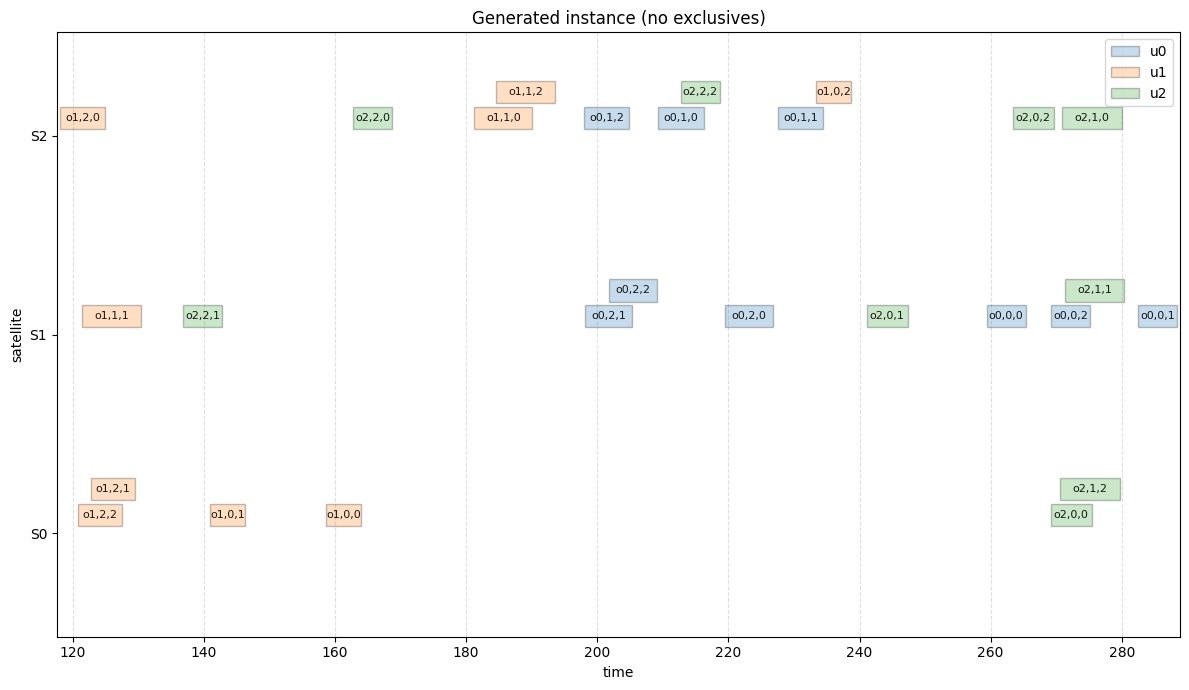

In [732]:
plot_eoscsp_windows(eoscsp_1, title="Generated instance (no exclusives)", show_labels=True,
    show_exclusives=True,
    show_plan_labels=True,)

#### 2.1.5 - Ajout de l'exclusivité

Rappel des modifications :
- User : e n'est plus à None, chaque fenêtre exclusive contient un satellite et un intervalle de temps
- Observation : si o est dans fenêtre exclusive alors o.u doit être propriétaire de cette exclusivité - si o appratient à u0 alors elle peut être dans une exclusivité ou hors de toutes les exclusivités 
- Contraintes globales : 1 - deux users différents ne peuvent pas utiliser la même exclusivité 2 - une observation non prioritaire ne peut pas intersecter une exclusivité
- Visualisation : zones hachurées du plot

In [733]:
horizon = 100.0

satellites = generate_satellites(3, horizon, 100, 200)
users_no_exclusifs = generate_users(1)
users_exclusifs = generate_users_exclusifs(len(users_no_exclusifs), satellites, 2)
users = users_no_exclusifs.union(users_exclusifs)
requests = generate_requests(users, 2, horizon, 3.0, 10.0, 5.0, 50.0)
observations = generate_observations(satellites, users, requests, 3, 6.0, 20.0)

eoscsp_2 = generate_EOSCSP(1, satellites, users, requests, observations)

print(f"Generated: |S|={len(satellites)} |U|={len(users)} |R|={len(requests)} |O|={len(observations)}")

Generated: |S|=3 |U|=2 |R|=4 |O|=12


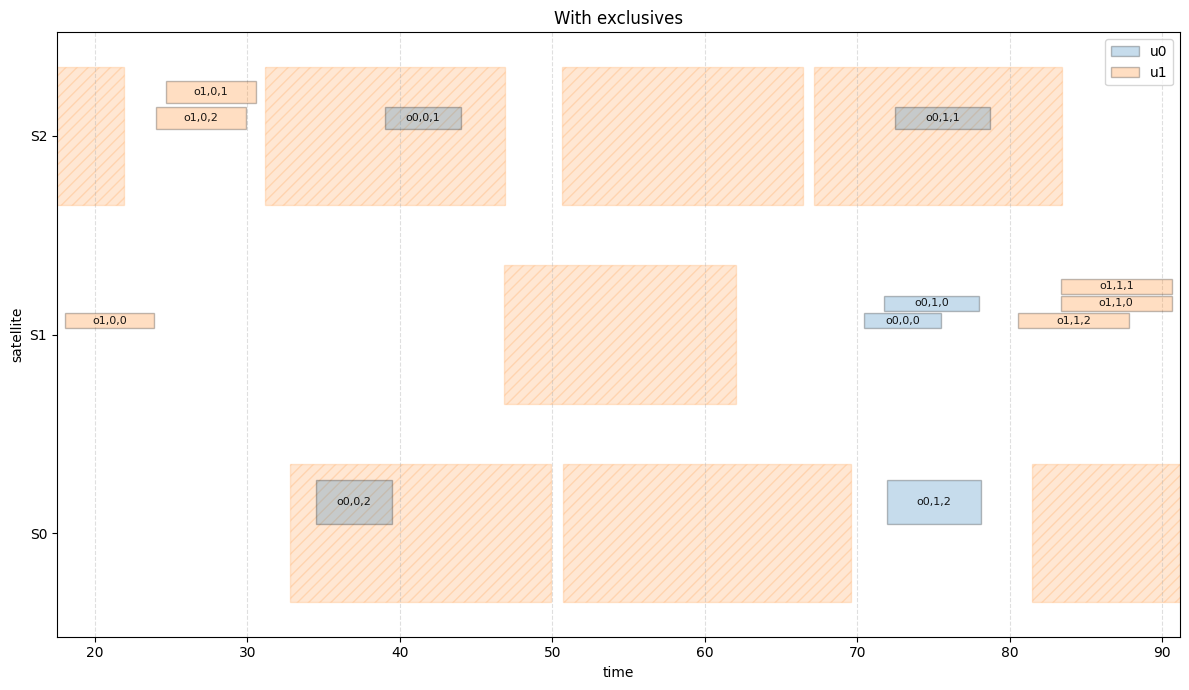

In [734]:
plot_eoscsp_windows(eoscsp_2, title="With exclusives", show_exclusives=True)

### 2.2 - Méthode de planification

Dans un second temps, nous allons concevoir une méthode de planification permettant à un utilisateur de planifier l’exécution d’un ensemble de tâches sur un satellite en tenant compte des contraintes temporelles sur ces tâches.

Dans le but de trouver une solution optimale du plan calculé, mais en limitant tout de même le temps de calcul nécessaire à cette génération, nous comptons implémenter une heuristique gloutonne.

DETAILLER PLUS TARD L'HEURISTIQUE SELON LE CHOIX D'IMPLEMENTATION


RAJOUTER NOTION DE PRIORITE OBSERVATION

#### Contraintes pour la solution

In [735]:
def feasible_window(o, start): # (10)
    return start + o.duration <= o.t_end

In [736]:
def feasible_transition(prev, prev_end, curr, start, tau, eps=1e-9):  # (5)(6)
    return start >= prev_end + tau(prev, curr) - eps

In [737]:
def feasible_no_overlap(o, start, end, plan, eps=1e-9): # non chevauchement réel
    o_sid = getattr(o.s, "s_id", o.s)

    for (obs2, s2, e2) in plan:
        s2_sid = getattr(obs2.s, "s_id", obs2.s)

        # satellites différents => aucun conflit
        if s2_sid != o_sid:
            continue

        # même satellite => pas de chevauchement autorisé
        if overlap(start, end, s2, e2, eps=eps):
            return False

    return True

In [738]:
def feasible_capacity(plan, sat): # (7)
    return len(plan) < sat.kappa

In [739]:
def feasible_one_obs_per_request(o, selected_requests): # (8)
    return o.r not in selected_requests

In [740]:
def feasible_exclusive(o, start, end, users): # exclusives (exécution réelle)
    for u in users:
        for (s,xs,xe) in u.e:
            if s == o.s and overlap(start, end, xs, xe):
                return o.u == u
    return True

### Helpers

In [766]:
def is_exclusive(u):
    return bool(getattr(u, "e", None))

def overlaps_strict(a1, a2, b1, b2):
    return max(a1, b1) < min(a2, b2)

def iter_exclusive_windows_on_sat(u, s):
    for item in getattr(u, "e", []) or []:
        if isinstance(item, tuple) and len(item) == 3:
            sat, xs, xe = item
        elif isinstance(item, tuple) and len(item) == 2 and isinstance(item[1], tuple):
            sat, (xs, xe) = item
        else:
            continue
        if sat == s:
            yield float(xs), float(xe)

def domains_for(o, u):
    if not is_exclusive(u):
        yield (o.s, float(o.t_start), float(o.t_end))
        return

    ok = False
    for xs, xe in iter_exclusive_windows_on_sat(u, o.s):
        a = max(float(o.t_start), xs)
        b = min(float(o.t_end), xe)
        if a <= b:
            ok = True
            yield (o.s, a, b)
    if not ok:
        return

def overlaps_any_exclusive_interval(sat, start, end, U_ex):
    for uex in U_ex:
        for xs, xe in iter_exclusive_windows_on_sat(uex, sat):
            if overlaps_strict(float(start), float(end), float(xs), float(xe)):
                return True
    return False

def plan_reward(plan):
    return sum(float(getattr(o, "reward", getattr(o, "rho", 0.0)) or 0.0) for o, _, _ in plan)

#### Génération d'une solution

In [741]:
def gaps(plan, t_min, t_max):
    if not plan:
        return [(t_min, t_max, None, None)]

    plan = sorted(plan, key=lambda x: x[1])
    res = []

    # before first
    first = plan[0]
    if t_min < first[1]:
        res.append((t_min, first[1], None, first))

    # between
    for i in range(len(plan) - 1):
        prev_item = plan[i]
        next_item = plan[i + 1]
        if prev_item[2] < next_item[1]:
            res.append((prev_item[2], next_item[1], prev_item, next_item))

    # after last
    last = plan[-1]
    if last[2] < t_max:
        res.append((last[2], t_max, last, None))
    return res

In [742]:
# # Vraiment utile ? hmmmmm
# def check_plan_constraints(plan, users, sat, tau, p: 0.0, eps=1e-9):
#     errors = []

#     # (7) Capacité satellite
#     if len(plan) > sat.kappa:
#         errors.append(
#             f"(7) Capacity violated: |plan|={len(plan)} > kappa={sat.kappa}"
#         )

#     # (10) Fenêtres temporelles des observations
#     for (o, s_exec, e_exec) in plan:
#         if not (o.t_start - eps <= s_exec and e_exec <= o.t_end + eps):
#             errors.append(
#                 f"(10) Window violated for obs o{getattr(o,'o_id','?')}: "
#                 f"planned [{s_exec:.2f},{e_exec:.2f}] "
#                 f"not in [{o.t_start:.2f},{o.t_end:.2f}]"
#             )

#     # Non-chevauchement + (5)(6) transitions
#     plan_sorted = sorted(plan, key=lambda x: x[1])
#     for (o1, s1, e1), (o2, s2, e2) in zip(plan_sorted, plan_sorted[1:]):

#         # Non-chevauchement strict
#         if overlap(s1, e1, s2, e2, eps=eps):
#             errors.append(
#                 f"Overlap violated between obs o{getattr(o1,'o_id','?')} "
#                 f"and o{getattr(o2,'o_id','?')}"
#             )

#         # (5)(6) Transition tau
#         if s2 < e1 + tau(o1, o2) - eps:
#             errors.append(
#                 f"(5)(6) Transition violated between obs o{getattr(o1,'o_id','?')} "
#                 f"and o{getattr(o2,'o_id','?')}: "
#                 f"start2={s2:.2f} < end1+tau={e1+tau(o1,o2):.2f}"
#             )

#     # (8) Une observation au plus par requête
#     seen_requests = set()
#     for (o, _, _) in plan:
#         r = getattr(o, "r", None)
#         if r is None:
#             continue
#         if r in seen_requests:
#             errors.append(
#                 f"(8) Request duplicated: r{getattr(r,'r_id','?')}"
#             )
#         seen_requests.add(r)

#     # Exclusives : seul le propriétaire peut exécuter dans sa fenêtre exclusive
#     for (o, s_exec, e_exec) in plan:
#         for u in users:
#             for (s_ex, xs, xe) in getattr(u, "e", []) or []:
#                 if getattr(s_ex, "s_id", None) != getattr(o.s, "s_id", None):
#                     continue
#                 if overlap(s_exec, e_exec, xs, xe, eps=eps):
#                     if o.u.u_id != u.u_id:
#                         errors.append(
#                             f"Exclusive violated on S{getattr(o.s,'s_id','?')}: "
#                             f"obs o{getattr(o,'o_id','?')} (u{o.u.u_id}) "
#                             f"overlaps exclusive of u{u.u_id} "
#                             f"[{xs:.2f},{xe:.2f}]"
#                         )

#     return errors


In [743]:
def generate_solution(tasks, users=None, lam=0.1, eps=1e-6, tau=tau, sol_id=0, debug=False):
    if not tasks:
        return Solution(sol_id, {}), 0.0, []

#     if tau is None:
#         tau = lambda a, b: 1.0

    # mono-satellite
    sids = {getattr(t.s, "s_id", id(t.s)) for t in tasks}
    if len(sids) != 1:
        raise ValueError("generate_solution() attend des tasks d'un seul satellite")

    sat = tasks[0].s
    t_min, t_max = sat.t_start, sat.t_end

    def score(o):
        slack = o.t_end - o.t_start
        return (o.reward / o.duration) + lam * (1.0 / max(slack, eps))

    tasks_sorted = sorted(tasks, key=lambda o: (-score(o), o.t_end))

    plan = []
    tot_reward = 0.0
    selected_requests = set()   # (8) one obs per request

    for o in tasks_sorted:
        # (7) capacity kappa
        if not feasible_capacity(plan, sat):
            break

        # (8) one obs per request
        if not feasible_one_obs_per_request(o, selected_requests):
            continue

        best_start = None
        candidate_gaps = gaps(plan, t_min=t_min, t_max=t_max)

        for (g_start, g_end, prev_item, next_item) in candidate_gaps:
            start = max(o.t_start, g_start)
            end = start + o.duration

            # (10) fenêtre de l'observation + doit tenir dans le gap
            if not feasible_window(o, start):
                continue
            if end > g_end + eps:
                continue

            # (5)(6) transition avec le précédent (si existe)
            if prev_item is not None:
                prev_obs, prev_start, prev_end = prev_item
                if not feasible_transition(prev_obs, prev_end, o, start, tau, eps=eps):
                    continue

            # (5)(6) transition avec le suivant (si existe)
            if next_item is not None:
                next_obs, next_start, next_end = next_item
                if end + tau(o, next_obs) > next_start + eps:
                    continue

            # Non-chevauchement (sécurité)
            if not feasible_no_overlap(o, start, end, plan, eps=eps):
                continue

            # Exclusives (exécution réelle)
            if users is not None and not feasible_exclusive(o, start, end, users):
                continue

            best_start = start
            break

        if best_start is not None:
            plan.append((o, best_start, best_start + o.duration))
            plan.sort(key=lambda x: x[1])
            tot_reward += o.reward
            selected_requests.add(o.r)

    # Optionnel: validation globale (debug)
#     if debug and users is not None:
#         errs = check_plan_constraints(plan, users, sat, tau=tau)
#         if errs:
#             raise RuntimeError("Plan violates constraints:\n- " + "\n- ".join(errs))

    M = {obs: start for (obs, start, end) in plan}
    return Solution(sol_id=sol_id, M=M), tot_reward, plan


In [768]:
def first_slot(o, u, R, tau):
    """
    ⊕ insertion faisable dans la timeline R (dict sat->list[(obs,start)] triée).
    Retourne t si insertion OK, sinon None.
    """
    s = o.s
    if len(R[s]) >= s.kappa:
        return None

    for sat, t_start, t_end in domains_for(o, u):
        # timeline vide
        if len(R[sat]) == 0:
            if float(t_start) + float(o.duration) <= float(t_end):
                R[sat].append((o, float(t_start)))
                return float(t_start)
            continue

        i = 0
        while i <= len(R[sat]):
            t_prime = float(t_start)

            if i > 0:
                o_prev, t_prev = R[sat][i - 1]
                t_prime = max(
                    t_prime,
                    float(t_prev) + float(o_prev.duration) + float(tau(o_prev, o))
                )

            if t_prime + float(o.duration) <= float(t_end):
                if i == len(R[sat]):
                    R[sat].insert(i, (o, t_prime))
                    return t_prime
                else:
                    o_next, t_next = R[sat][i]
                    t_upper = float(t_next) - float(o.duration) - float(tau(o, o_next))
                    if t_prime <= t_upper:
                        R[sat].insert(i, (o, t_prime))
                        return t_prime

            i += 1

    return None

def greedy_solver(P, tau, u=None, restrict_to_exclusives=False, obs_pool=None):
    """
    Greedy EOSCSP solver conforme à l'Algorithm 1 du papier.

    Retour:
      M_dict : {obs: start_time}
      reward : somme des rewards
      plan   : [(obs,start,end)] trié

    Paramètres:
      - u: si fourni => ne considère que les obs o.u == u
      - restrict_to_exclusives: si True => domains_for(o,u) restreint aux exclusives de u
      - obs_pool: si fourni => remplace P.O comme ensemble d'observations candidates
                  (utile pour bid_marginal: pool = obs_u ∪ obs_r)
    """
    # 1) M <- {}
    M_dict = {}

    # 2) O_sorted <- sort(O)
    if obs_pool is None:
        O_sorted = list(P.O)
    else:
        O_sorted = list(obs_pool)

    if u is not None:
        O_sorted = [o for o in O_sorted if o.u == u]

    O_sorted.sort(key=lambda o: (getattr(o, "p", 0), float(o.t_start)))

    # 3) R <- {(s, []) | s in S}
    R = {s: [] for s in P.S}

    # contexte user pour domains_for()
    if restrict_to_exclusives:
        if u is None:
            raise ValueError("restrict_to_exclusives=True nécessite de fournir u.")
        u_ctx = u
    else:
        u_ctx = type("NonExclusiveUser", (), {"e": []})()

    # 4) for o in O_sorted do
    i = 0
    while i < len(O_sorted):
        o = O_sorted[i]

        # 5) t <- first_slot(o, P, R)
        t = first_slot(o, u_ctx, R, tau)

        # 6) if t != ∅ then
        if t is not None:
            # 7) M <- M ∪ {(o,t)}
            M_dict[o] = float(t)

            # 8) O_sorted <- O_sorted \ theta(r_o)
            r = getattr(o, "r", None)
            if r is not None:
                O_sorted = [oo for oo in O_sorted if getattr(oo, "r", None) != r]
                continue

        i += 1

    plan = [(o, t, t + float(o.duration)) for o, t in M_dict.items()]
    plan.sort(key=lambda x: x[1])
    reward = plan_reward(plan)
    return M_dict, reward, plan

In [769]:
def observations_one_user_one_satellite(observations, u_id, s_id):
    tasks = []
    for o in observations :
        if o.u.u_id == u_id and o.s.s_id == s_id:
            tasks.append(o)
    return tasks

#### Test sur une instance

In [745]:
horizon = 100.0

satellites = generate_satellites(3, horizon, 100, 200)
users_no_exclusifs = generate_users(1)
users_exclusifs = generate_users_exclusifs(len(users_no_exclusifs), satellites, 2)
users = users_no_exclusifs.union(users_exclusifs)
requests = generate_requests(users, 2, horizon, 3.0, 10.0, 5.0, 50.0)
observations = generate_observations(satellites, users, requests, 3, 6.0, 20.0)

eoscsp_2 = generate_EOSCSP(1, satellites, users, requests, observations)

# user 0 et satellite 0
observations_u0 = observations_one_user_one_satellite(observations, 0, 0)

solution, reward, plan = generate_solution(observations_u0, tau=tau)

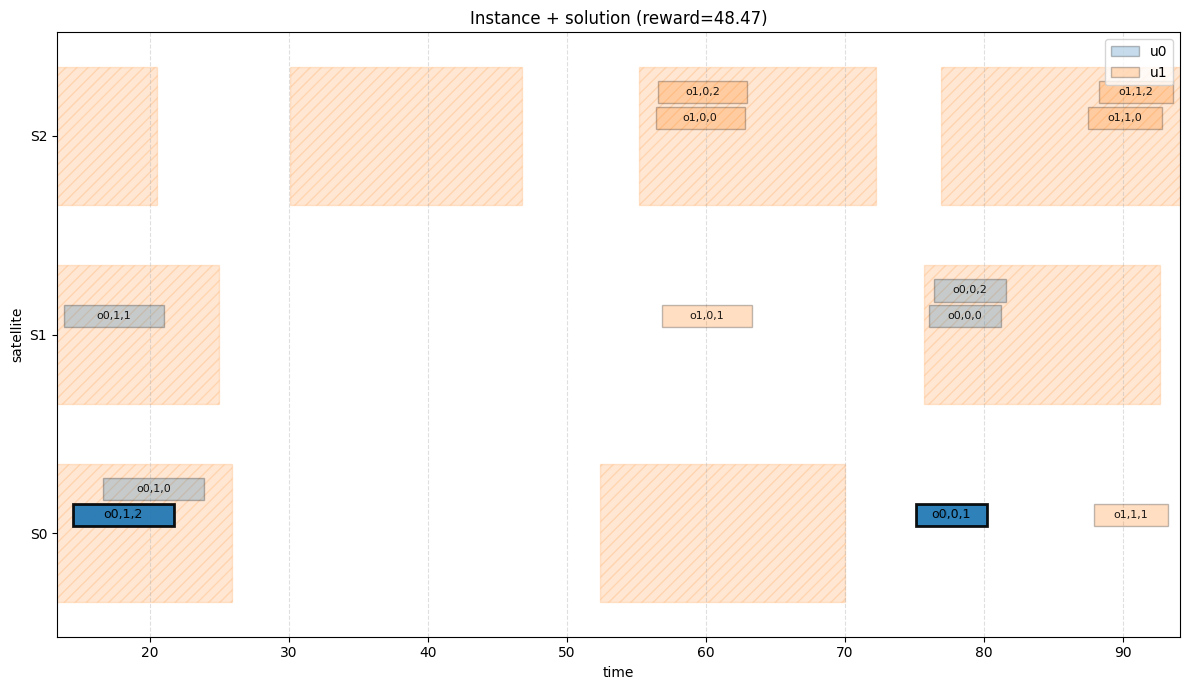

In [746]:
plot_eoscsp_windows(
    eoscsp_2,
    plan=plan,
    title=f"Instance + solution (reward={reward:.2f})",
    show_exclusives=True,
    show_labels=True,  
    show_plan_labels=True
)

In [747]:
# instance
P = generate_EOSCSP(2, satellites, users, requests, observations)
print(format_eoscsp(P, max_items=50))

EOSCSP instance #2
|S|=3 |U|=2 |R|=4 |O|=12

Satellites:
  S0: horizon=[0.00,100.00] kappa=129
  S1: horizon=[0.00,100.00] kappa=190
  S2: horizon=[0.00,100.00] kappa=153

Users:
  u0: priority=4 exclusives=0
  u1: priority=4 exclusives=8
    - (S0, [9.16,25.87])
    - (S0, [52.34,70.01])
    - (S1, [7.54,24.99])
    - (S1, [75.70,92.67])
    - (S2, [4.01,20.48])
    - (S2, [30.07,46.79])
    - (S2, [55.17,72.23])
    - (S2, [76.91,95.11])

Requests:
  r0: user=u0 duration=5.142143463980056 reward=18.85096158837761
  r1: user=u0 duration=7.243623100433893 reward=29.62222417250844
  r2: user=u1 duration=6.416882273394722 reward=38.315865667291646
  r3: user=u1 duration=5.311628395849622 reward=6.451825817823982

Observations (windows):
  o8: u0 on S0 window=[14.45,21.69] dur=7.24 reward=29.62 (r1)
  o6: u0 on S0 window=[16.64,23.88] dur=7.24 reward=29.62 (r1)
  o1: u0 on S0 window=[75.09,80.23] dur=5.14 reward=18.85 (r0)
  o4: u1 on S0 window=[87.94,93.26] dur=5.31 reward=6.45 (r3)
  o7

In [748]:
print(format_solution(solution, title="Greedy planning solution"))

Greedy planning solution
Planned observations: 2

Total reward (sum of planned observations): 48.47

Satellite S0:
  o8 (r1 u0): start=14.45 end=21.69 dur=7.24 reward=29.62
  o1 (r0 u0): start=75.09 end=80.23 dur=5.14 reward=18.85


## 3 - Partie 1 : Optimisation de contraintes distribuées

Dans cette partie, nous allons générer 

In [749]:
import pydcop
import yaml
import os

In [750]:
def intersect(a_start, a_end, b_start, b_end):
    return max(a_start, b_start), min(a_end, b_end)

#### DCOP Model

Dans un premier temps, nous récupérons l'ensemble des agents exclusifs capables de répondre à la requête r, leurs fenêtres exclusives, et les observations compatibles. (13)

In [751]:
def compute_A_and_Oru(r, theta_r_obs, Uex, eps=1e-9):
    A = []
    Oru = {}
    E_u = {}

    for u in Uex:
        uid = u.u_id
        exclus = list(getattr(u, "e", []) or [])
        E_u[uid] = exclus

        obs_ok = []
        for o in theta_r_obs:
            for (s, xs, xe) in exclus:
                if getattr(s, "s_id", None) != getattr(o.s, "s_id", None):
                    continue
                if overlap(xs, xe, o.t_start, o.t_end, eps=eps):
                    obs_ok.append(o)
                    break

        if obs_ok:
            A.append(u)
            Oru[uid] = obs_ok

    return A, Oru, E_u


Cette fonction nous permet d'évaluer la capacité des satellites, afin de respecter la contrainte de capacité des satellites. (16)

In [752]:
def remaining_capacity_by_satellite(EOSCSP, plans_u):
    used = {}
    for sat in EOSCSP.S:
        sid = sat.s_id
        used[sid] = 0

    for uid, plan in plans_u.items():
        for (o, st, en) in plan:
            sid = o.s.s_id
            used[sid] = used.get(sid, 0) + 1

    kappa_star = {}
    for sat in EOSCSP.S:
        sid = sat.s_id
        kappa_star[sid] = max(0, sat.kappa - used.get(sid, 0))

    return kappa_star


Celle-ci nous rend la fonction objectif afin de maximiser la solution.

In [753]:
def plan_reward(plan):
    return sum(obs.reward for (obs, st, en) in plan)

def pi_cost(o, plan_u, users, lam=0.1, tau=None):
    # On ne garde que les tâches du même satellite que o
    sid_o = getattr(o.s, "s_id", id(o.s))
    tasks_same_sat = [obs for (obs, st, en) in plan_u
                      if getattr(obs.s, "s_id", id(obs.s)) == sid_o]

    # reward avant, sur ce satellite uniquement
    plan_u_same_sat = [(obs, st, en) for (obs, st, en) in plan_u
                       if getattr(obs.s, "s_id", id(obs.s)) == sid_o]
    rew1 = plan_reward(plan_u_same_sat)

    # reward après ajout de o, en réoptimisant seulement ce satellite
    sol2, rew2, plan2 = generate_solution(tasks_same_sat + [o], users=users, lam=lam, tau=tau)

    # coût positif si on perd du reward ; 0 si on gagne
    return max(0.0, rew1 - rew2)



In [754]:
def feasible_start_in_exclusive(o, e, eps=1e-9):
    s, xs, xe = e
    if s.s_id != o.s.s_id:
        return None
    a, b = intersect(xs, xe, o.t_start, o.t_end)
    start = a
    if start + o.duration <= b + eps:
        return start
    return None

#### Création fichier yaml

Le temps est discrétisé avec un pas Δ afin de limiter la taille des domaines et rendre le problème traitable par un solveur DCOP.

In [755]:
import yaml
from pathlib import Path

BIG = 10**6

def build_dcop_request_faithful(
    EOSCSP,
    r,
    theta_r_obs,
    Uex,
    plans_u,
    users_all,
    lam=0.1,
    tau=None,
    out_yaml_path="req.yaml",
    eps=1e-9
):
    A, Oru, E_u = compute_A_and_Oru(r, theta_r_obs, Uex, eps=eps)
    kappa_star = remaining_capacity_by_satellite(EOSCSP, plans_u)

    domains = {"bin": {"values": [0, 1]}}
    variables = {}
    constraints = {}
    agents = [f"u{u.u_id}" for u in A]

    # index pour contrainte "at most one obs for request"
    all_vars = []

    # (X) Construire variables x_{e,o} qui sont réellement faisables
    # et stocker les infos nécessaires (sat, start, end, obs)
    var_info = {}  # var -> (uid, obs, satid)
    for u in A:
        uid = u.u_id
        for e in E_u[uid]:
            for o in Oru[uid]:
                st = feasible_start_in_exclusive(o, e, eps=eps)
                if st is None:
                    continue
                var = f"x_u{uid}_s{o.s.s_id}_o{o.o_id}_e{round(e[1],3)}"
                variables[var] = {"domain": "bin"}
                all_vars.append(var)
                var_info[var] = (uid, o, o.s.s_id, st, st + o.duration)

                # (18) soft cost: c(x)=pi(o, M_u) if x=1 else 0
                cost = pi_cost(o, plans_u.get(uid, []), users_all, lam=lam, tau=tau)
                constraints[f"cost_{var}"] = {
                    "type": "intention",
                    "function": f"{cost} if {var} == 1 else 0"
                }

    # (15) au plus UNE variable x_{e,o} == 1 (pour cette requête)
    if all_vars:
        cnt = " + ".join(all_vars)
        constraints["one_obs_for_request"] = {
            "type": "intention",
            "function": f"{BIG} if ({cnt}) > 1 else 0"
        }

    # (16) capacité satellite restante
    # Somme des x liés à un satellite s <= kappa_star[s]
    # (NB: fidèle au passage, mais en vrai, ici on ajoute au plus 1 obs, donc c'est souvent triviale)
    for sat in EOSCSP.S:
        sid = sat.s_id
        cap = kappa_star.get(sid, sat.kappa)
        vars_on_sat = [v for v,info in var_info.items() if info[2] == sid]
        if vars_on_sat:
            cnt = " + ".join(vars_on_sat)
            constraints[f"cap_s{sid}"] = {
                "type": "intention",
                "function": f"{BIG} if ({cnt}) > {cap} else 0"
            }

    # (17) au plus un agent sert la même observation o
    # Somme des x_{*,o} <= 1 pour chaque o
    obs_to_vars = {}
    for v, (uid, o, sid, st, en) in var_info.items():
        obs_to_vars.setdefault(o.o_id, []).append(v)

    for oid, vars_for_o in obs_to_vars.items():
        if len(vars_for_o) > 1:
            cnt = " + ".join(vars_for_o)
            constraints[f"one_agent_for_o{oid}"] = {
                "type": "intention",
                "function": f"{BIG} if ({cnt}) > 1 else 0"
            }

    dcop = {
        "name": f"s_dcop_req_{r.r_id}",
        "objective": "min",
        "domains": domains,
        "variables": variables,
        "constraints": constraints,
        "agents": agents
    }

    out_yaml_path = str(Path(out_yaml_path))
    with open(out_yaml_path, "w", encoding="utf-8") as f:
        yaml.safe_dump(dcop, f, sort_keys=False, allow_unicode=True)

    return out_yaml_path, var_info


#### Algorithmes Pydcop

Maintenant le DCOP réalisé, nous allons continuer l'algorithme décrit dans l'article dans le but de le résoudre. C'est pourquoi, nous avons implémenté une fonction permettant d'appliquer différents algorithmes de la librairie pydcop.

In [756]:
import subprocess
import shlex
from pathlib import Path

def solve_dcop(
    yaml_path,
    algo,
    timeout_s = None,
    algo_params = None,
    extra_args = None,
    cwd = None,
):

    yaml_path = str(Path(yaml_path))

    cmd = ["pydcop", "solve", "--algo", algo]

    if timeout_s is not None:
        cmd += ["--timeout", str(timeout_s)]

    if algo_params:
        # format CLI pyDCOP: --algo_params key:value,key2:value2
        ap = ",".join(f"{k}:{v}" for k, v in algo_params.items())
        cmd += ["--algo_params", ap]

    if extra_args:
        cmd += extra_args

    cmd.append(yaml_path)

    proc = subprocess.run(
        cmd,
        capture_output=True,
        text=True,
        cwd=cwd
    )
    return proc.returncode, proc.stdout, proc.stderr


In [757]:
def apply_dcop_decision(assignment, var_info, plans_u):
    chosen = [v for v,val in assignment.items() if str(val) in ("1", "1.0", "True")]
    for v in chosen:
        if v not in var_info:
            continue
        uid, obs, sid, st, en = var_info[v]
        plans_u.setdefault(uid, []).append((obs, st, en))
        plans_u[uid].sort(key=lambda x: x[1])

In [774]:
import re

def parse_assignment_from_stdout(stdout):
    assignment = {}

    # regex: variable = value  ou  variable: value
    pattern = re.compile(
        r"(x_[A-Za-z0-9_\.]+)\s*(?:=|:|->)\s*([01])"
    )

    for line in stdout.splitlines():
        line = line.strip()
        m = pattern.search(line)
        if m:
            var = m.group(1)
            val = int(m.group(2))
            assignment[var] = val

    return assignment

Nos fonctions nécessaires à l'algorithme décrit dans l'article étant construites, nous détaillons désormais l'algorithme de solver EOSCSP étape par étape.

In [759]:
def s_dcop_EOSCSP_solver(P, tau, algo="dsa"):
    plans_u = dict()
    observations_to_sup = set()

    # --- Étape 1 : plans initiaux des users exclusifs
    for u in P.U:
        if not u.e:
            continue

        plans_u[u.u_id] = []
        for (s, xs, xe) in u.e:
            obs_u_s = observations_one_user_one_satellite(P.O, u.u_id, s.s_id)
            sol, _, plan = generate_solution(obs_u_s, users=P.U, tau=tau)
            plans_u[u.u_id].extend(plan)
            
        plans_u[u.u_id].sort(key=lambda x: x[1])

    # --- Étape 2 : boucle sur les requêtes
    for r in sorted(P.R, key=lambda r: r.t_end):
        theta_r = [o for o in P.O if o.r == r]
        if not theta_r:
            continue
            
        yaml_path, var_info = build_dcop_request_faithful(
            EOSCSP=P,
            r=r,
            theta_r_obs=theta_r,
            Uex=[u for u in P.U if u.e],
            plans_u=plans_u,
            users_all=P.U,
            tau=tau,
        )
        
        rc, out, err = solve_dcop(yaml_path, algo=algo)
        if rc != 0:
            continue

        assignment = parse_assignment_from_stdout(out)
        apply_dcop_decision(assignment, var_info, plans_u)

        
    for plan in plans_u.values():
        for (o, start, end) in plan:
            observations_to_sup.add(o)
    
    
    for u in P.U:
        if u.e:
            continue
            
        plans_u[u.u_id] = []

        obs_u = [
            o for o in P.O
            if o.u.u_id == u.u_id and o not in observations_to_sup
        ]

        if not obs_u:
            plans_u[u.u_id] = []
            continue

        # regrouper les observations par satellite
        obs_by_sat = {}
        for o in obs_u:
            sid = o.s.s_id
            obs_by_sat.setdefault(sid, []).append(o)
            
        # planifier satellite par satellite
        for sid, obs_u_s in obs_by_sat.items():
            sol, _, plan = generate_solution(
                obs_u_s,
                users=P.U,
                tau=tau,
            )
            plans_u[u.u_id].extend(plan)

        # trier le plan final du user
        plans_u[u.u_id].sort(key=lambda x: x[1])
    
    global_plan = []
    for plan in plans_u.values():
        global_plan.extend(plan)

    return plans_u, global_plan

#### Tests

In [795]:
horizon = 100.0

satellites = generate_satellites(3, horizon, 100, 200)
users_no_exclusifs = generate_users(1)
users_exclusifs = generate_users_exclusifs(len(users_no_exclusifs), satellites, 2)
users = users_no_exclusifs.union(users_exclusifs)
requests = generate_requests(users, 2, horizon, 3.0, 10.0, 5.0, 50.0)
observations = generate_observations(satellites, users, requests, 3, 6.0, 20.0)

P = generate_EOSCSP(1, satellites, users, requests, observations)


=== Final plans after s_dcop ===
User u1:
  obs o3 on S2 [10.5,15.5] r3
User u1:
  obs o3 on S2 [10.5,15.5] r3
User u1:
  obs o3 on S2 [10.5,15.5] r3
User u1:
  obs o11 on S2 [17.4,22.4] r2
User u1:
  obs o11 on S2 [17.4,22.4] r2
User u1:
  obs o11 on S2 [17.4,22.4] r2
User u2:
  obs o8 on S0 [17.7,22.7] r4
User u2:
  obs o8 on S0 [17.7,22.7] r4
User u2:
  obs o8 on S0 [17.7,22.7] r4


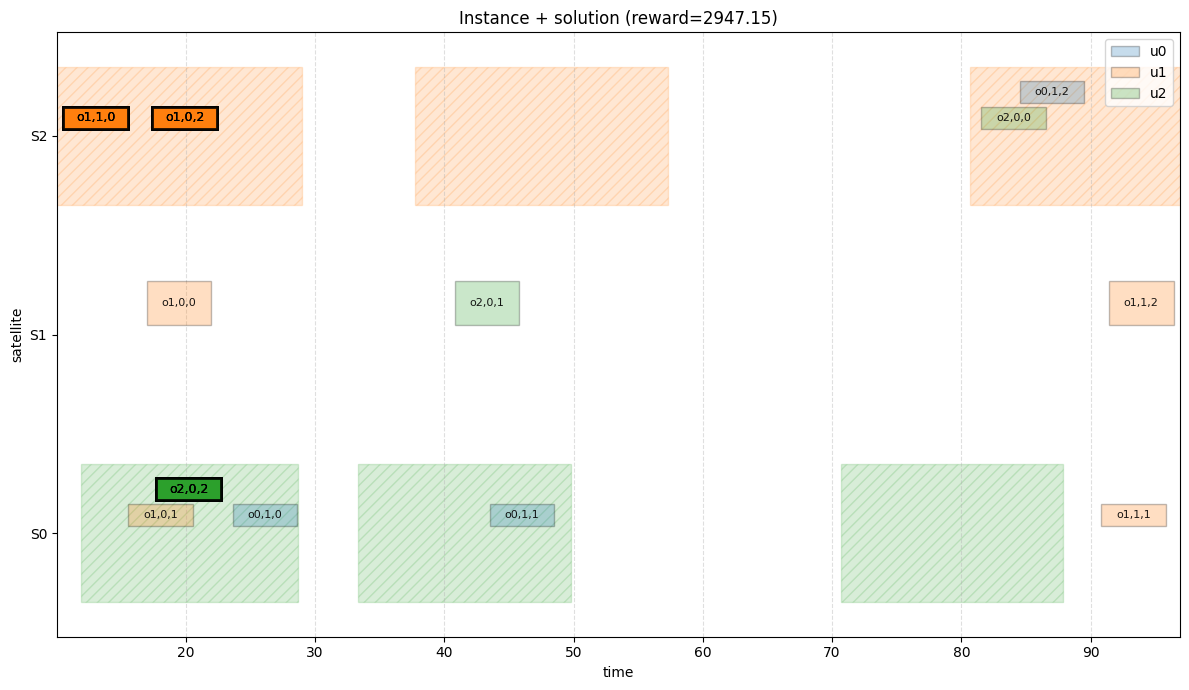

In [796]:
plans_u, global_plan = s_dcop_EOSCSP_solver(P, tau=tau)

print("\n=== Final plans after s_dcop ===")
for o, st, en in global_plan:
    print(f"User u{o.u.u_id}:")
    print(f"  obs o{o.o_id} on S{o.s.s_id} [{st:.1f},{en:.1f}] r{o.r.r_id}")

plot_eoscsp_windows(
P,
plan=global_plan,
title=f"Instance + solution (reward={reward:.2f})",
show_exclusives=True,
show_labels=True,  
show_plan_labels=True
)

#### Instance article fin

In [762]:
# ======================
# Paramètres globaux
# ======================
horizon = 300.0

NB_SAT = 3
CAPACITY = 20

NB_USERS_EXCL = 4
NB_USERS_CENTRAL = 1   # le planner central

# ======================
# Satellites
# ======================
satellites = generate_satellites(
    nb_satellites=NB_SAT,
    horizon=horizon,
    kappa_min=CAPACITY,
    kappa_max=CAPACITY
)

# ======================
# Utilisateur central (non exclusif)
# ======================
users_no_exclusifs = generate_users(
    nb_users=NB_USERS_CENTRAL,
    min_priority=1,
    max_priority=1      # optionnel : même priorité
)

# ======================
# Utilisateurs exclusifs
# ======================
users_exclusifs = generate_users_exclusifs(
    k=len(users_no_exclusifs),
    satellites=satellites,
    nb_users=NB_USERS_EXCL,
    k_excl_per_user=8,   # 8 exclusifs par user
    e_dur_min=15,
    e_dur_max=20
)

users = users_no_exclusifs.union(users_exclusifs)

# ======================
# Requêtes
# ======================

# --- requêtes des exclusifs : 2 à 20, reward discret [10,20,30,40,50]
requests_excl = generate_requests(
    users=users_exclusifs,
    nb_requests_per_user=None,
    nb_min=2,
    nb_max=20,
    horizon=horizon,
    d_min=10.0,
    d_max=20.0,
    r_min=10.0,
    r_max=50.0,
    reward_values=[10, 20, 30, 40, 50]
)

# --- requêtes du planner central : 8 à 80, reward [1..5]
requests_central = generate_requests(
    users=users_no_exclusifs,
    nb_requests_per_user=None,
    nb_min=8,
    nb_max=80,
    horizon=horizon,
    d_min=10.0,
    d_max=20.0,
    r_min=1.0,
    r_max=5.0,
    reward_values=[1, 2, 3, 4, 5]
)

requests = requests_excl.union(requests_central)

# ======================
# Observations
# ======================
observations = generate_observations(
    satellites=satellites,
    users=users,
    requests=requests,
    opp_per_request=10,     # 10 opportunités / requête
    obs_window_min=10.0,
    obs_window_max=20.0,
    opp_duration=5.0        # durée fixe = 5
)

# ======================
# Instance EOSCSP
# ======================
eoscsp_2 = generate_EOSCSP(
    1,
    satellites,
    users,
    requests,
    observations
)

# ======================
# Exemple : user 0 / satellite 0
# ======================



=== Running s_dcop with dsa ===
Total reward with dsa: 3056.00


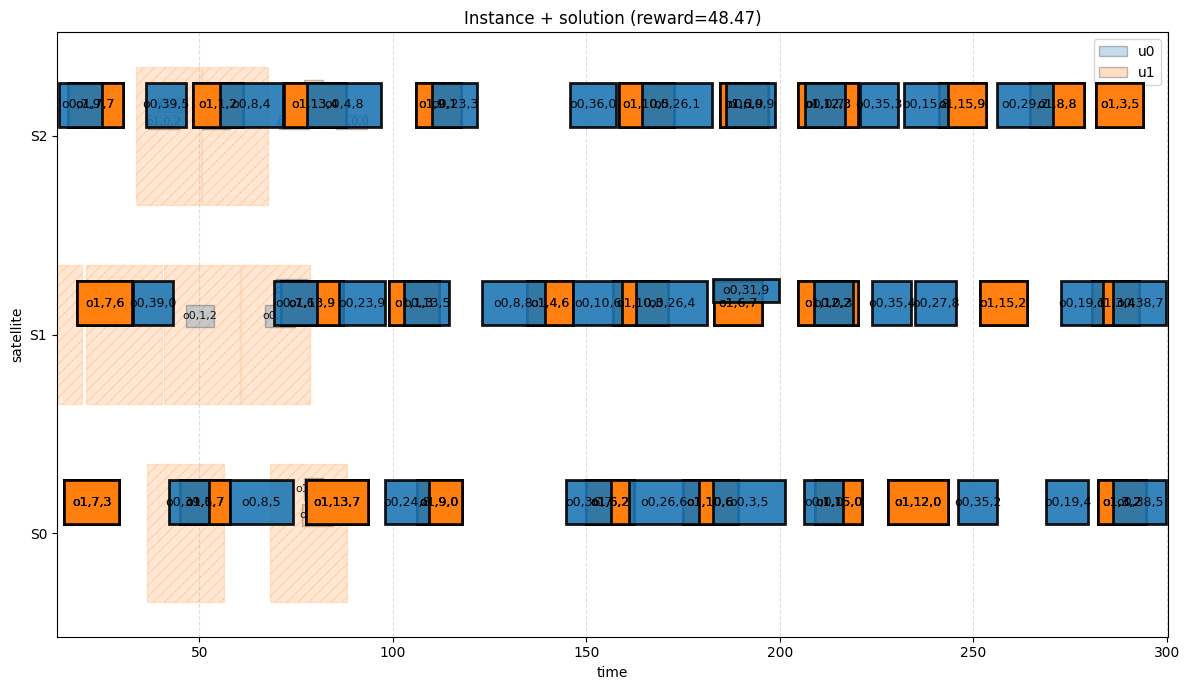


=== Running s_dcop with mgm ===
Total reward with mgm: 3056.00


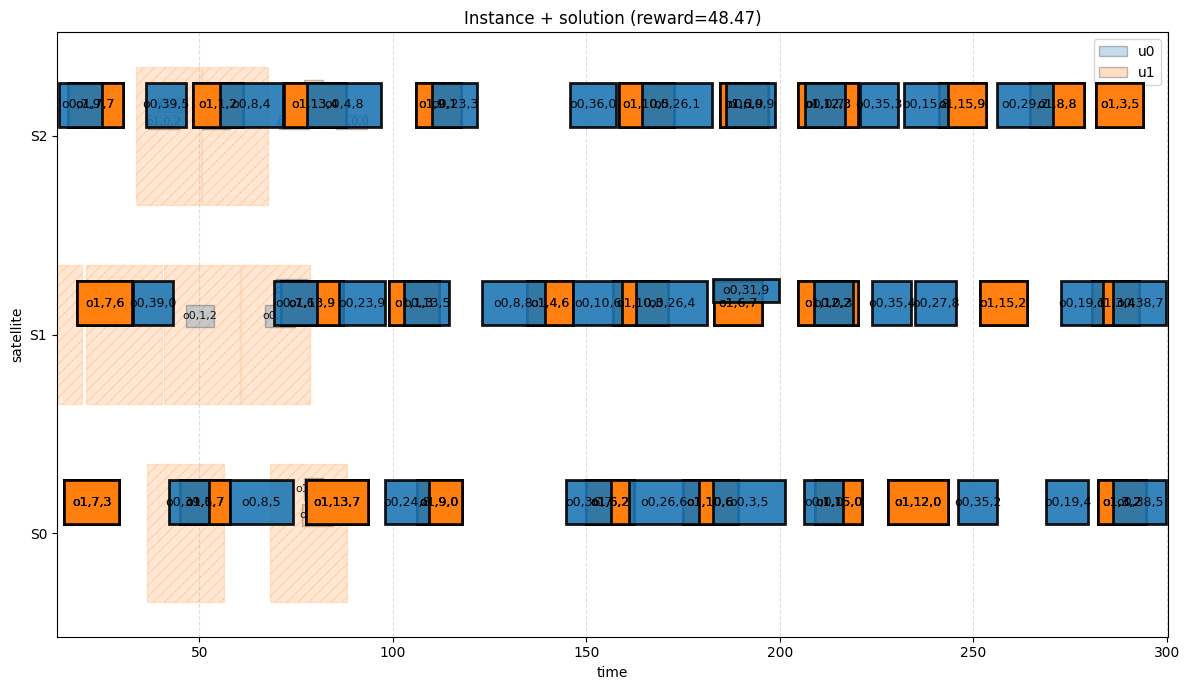


=== Running s_dcop with maxsum ===
Total reward with maxsum: 3056.00


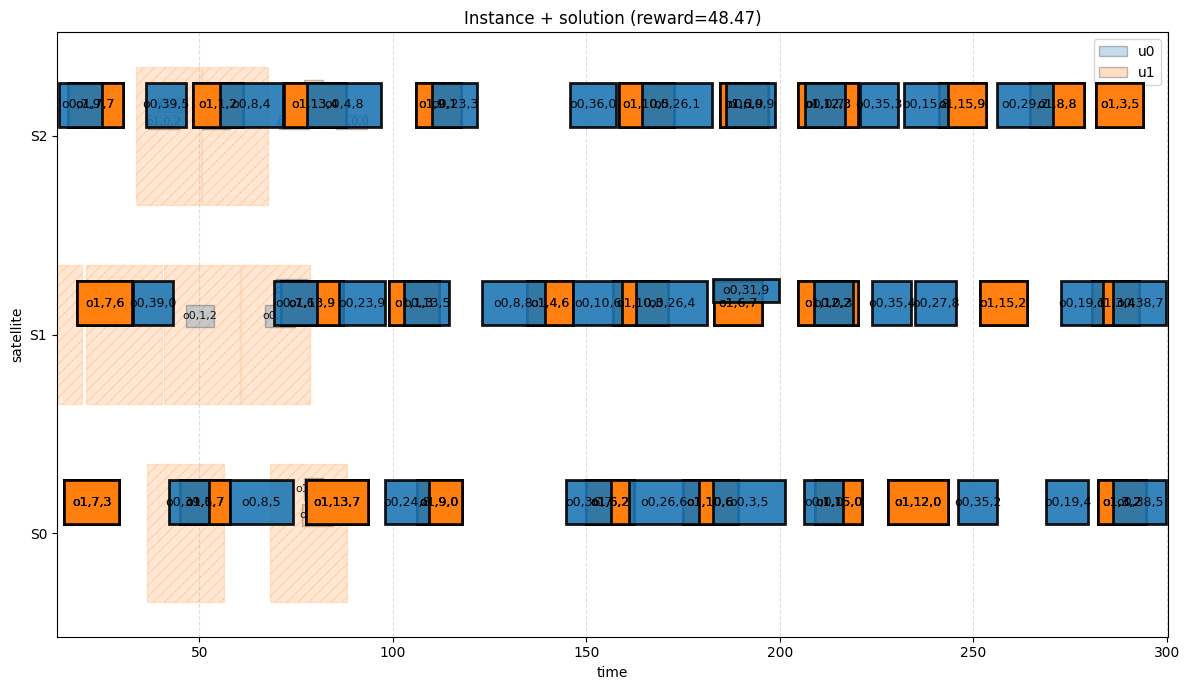


=== Running s_dcop with dpop ===
Total reward with dpop: 3056.00


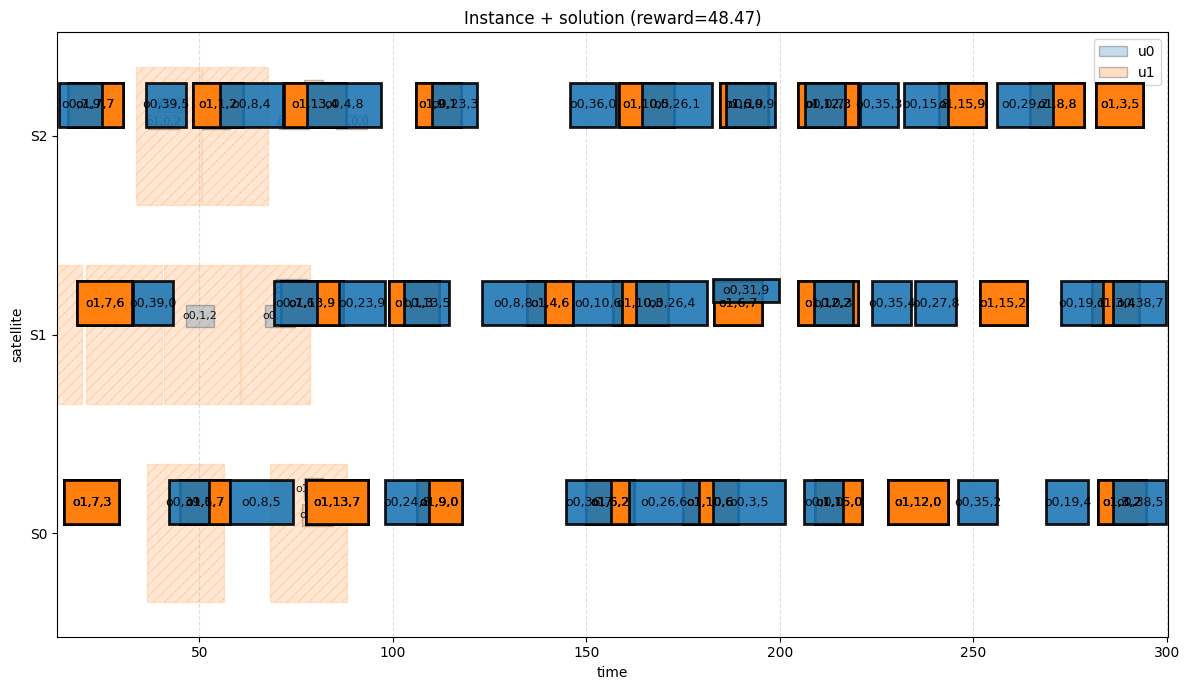

In [763]:

for algo in ["dsa", "mgm", "maxsum", "dpop"]:
    print(f"\n=== Running s_dcop with {algo} ===")
    plans_u, global_plan = s_dcop_EOSCSP_solver(eoscsp_2, tau=tau, algo=algo)
    total = sum(o.reward for plan in plans_u.values() for (o,_,_) in plan)
    print(f"Total reward with {algo}: {total:.2f}")
    plot_eoscsp_windows(
    P,
    plan=global_plan,
    title=f"Instance + solution (reward={reward:.2f})",
    show_exclusives=True,
    show_labels=True,  
    show_plan_labels=True
    )

In [764]:
print(format_eoscsp(P))

EOSCSP instance #1
|S|=3 |U|=2 |R|=4 |O|=12

Satellites:
  S0: horizon=[0.00,100.00] kappa=150
  S1: horizon=[0.00,100.00] kappa=178
  S2: horizon=[0.00,100.00] kappa=182

Users:
  u0: priority=9 exclusives=0
  u1: priority=4 exclusives=8
    - (S0, [36.56,56.34])
    - (S0, [68.26,88.14])
    - (S1, [2.18,19.61])
    - (S1, [20.71,40.36])
    - (S1, [40.86,60.57])
    - (S1, [60.86,78.73])
    - (S2, [33.73,50.49])
    - (S2, [50.58,67.69])

Requests:
  r0: user=u1 duration=8.002377973841682 reward=13.823621565561323
  r1: user=u1 duration=4.394497791570245 reward=47.96666924415291
  r2: user=u0 duration=7.861594402021043 reward=17.556572133044
  r3: user=u0 duration=7.334203895181649 reward=14.378281712679081

Observations (windows):
  o1: u1 on S0 window=[76.45,84.45] dur=8.00 reward=13.82 (r0)
  o8: u1 on S0 window=[76.93,81.93] dur=5.00 reward=47.97 (r1)
  o5: u0 on S1 window=[46.42,53.76] dur=7.33 reward=14.38 (r3)
  o10: u0 on S1 window=[66.93,74.79] dur=7.86 reward=17.56 (r2)
 

#### Graphiques

In [800]:
N_RUNS = 5
HORIZON = 100.0

def make_pydcop_runner(algo_name):
    def _run(P, tau):
        print(f"  -> calling s_dcop_EOSCSP_solver(algo={algo_name})", flush=True)
        plans_u, global_plan = s_dcop_EOSCSP_solver(P, tau=tau, algo=algo_name)
        # reward total = somme des rewards des obs planifiées
        reward = sum(o.reward for (o, st, en) in global_plan)
        print(f"  -> done algo={algo_name}, nobs={len(global_plan)}, reward={reward:.1f}", flush=True)
        return global_plan, float(reward)
    return _run

PYDCOP_ALGOS = ["dsa", "mgm", "maxsum", "dpop"]

ALGOS = {
    "DCOP_dsa": make_pydcop_runner("dsa"),
    "DCOP_mgm": make_pydcop_runner("mgm"),
    "DCOP_maxsum": make_pydcop_runner("maxsum"),
    "DCOP_dpop": make_pydcop_runner("dpop"),
}

SIZES = {
    "small":  dict(n_sats=3, n_non_ex=1, n_ex=3, req_per_user=4, obs_per_req=5),
    "medium": dict(n_sats=5, n_non_ex=2, n_ex=5, req_per_user=6, obs_per_req=6),
    "large":  dict(n_sats=7, n_non_ex=3, n_ex=7, req_per_user=8, obs_per_req=7),
}

DIFFICULTIES = {
    "easy": dict(
        dur_min=4.0, dur_max=10.0,     # durées plus longues
        slack_min=14.0, slack_max=28.0,# fenêtres moins larges
        ex_windows=2,                  # plus d'exclusives
        tau_kind="mild"
    ),
    "medium": dict(
        dur_min=6.0, dur_max=16.0,
        slack_min=8.0, slack_max=18.0,
        ex_windows=3,
        tau_kind="hard"                # transitions plus pénalisantes
    ),
    "hard": dict(
        dur_min=10.0, dur_max=24.0,
        slack_min=5.0, slack_max=10.0, # fenêtres très étroites
        ex_windows=4,                  
        tau_kind="hard"
    ),
}

def tau_from_kind(kind):
    if kind == "hard":
        return lambda a, b: 2.0
    return lambda a, b: 1.0

def ideal_upper_bound(P):
    """
    Upper bound "théorique": somme_{r} max_{o in theta(r)} reward(o)
    Ignore contraintes -> borne sup.
    """
    best = {}
    for o in P.O:
        r = getattr(o, "r", None)
        if r is None:
            continue
        rew = float(getattr(o, "reward", getattr(o, "rho", 0.0)) or 0.0)
        best[r] = max(best.get(r, 0.0), rew)
    return float(sum(best.values())) if best else 0.0

def generate_instance(size_cfg, diff_cfg, horizon=HORIZON):
    # satellites
    satellites = generate_satellites(size_cfg["n_sats"], horizon, 100, 200)

    # users
    users_no_ex = generate_users(size_cfg["n_non_ex"])

    # NEW: on génère n_ex users exclusifs, avec ex_windows zones chacun
    users_ex = generate_users_exclusifs(
        k=len(users_no_ex),
        satellites=satellites,
        nb_users=size_cfg["n_ex"],
        k_excl_per_user=diff_cfg["ex_windows"],
        e_dur_min=15.0,   # à ajuster si tu veux que ça suive "difficulty"
        e_dur_max=20.0
    )

    users = users_no_ex.union(users_ex)

    # requests
    requests = generate_requests(
        users,
        size_cfg["req_per_user"],
        horizon,
        diff_cfg["dur_min"],
        diff_cfg["dur_max"],
        5.0,
        50.0,
    )

    # observations
    observations = generate_observations(
        satellites,
        users,
        requests,
        size_cfg["obs_per_req"],
        diff_cfg["slack_min"],
        diff_cfg["slack_max"],
    )

    P = generate_EOSCSP(0, satellites, users, requests, observations)
    return P


def run_one_algo(algo_fn, P, tau):
    t0 = time.perf_counter()
    plan, reward = algo_fn(P, tau=tau)
    t1 = time.perf_counter()
    return (t1 - t0), float(reward), plan

# ----------------------------
# RUN BENCH
# ----------------------------
# stockage brut : dict[size][difficulty][algo] -> list of metrics dict
raw = {size: {diff: {a: [] for a in ALGOS} for diff in DIFFICULTIES} for size in SIZES}

for size_name, size_cfg in SIZES.items():
    for diff_name, diff_cfg in DIFFICULTIES.items():
        tau = tau_from_kind(diff_cfg["tau_kind"])

        for run in range(N_RUNS):
            print(f"[GEN] size={size_name} diff={diff_name} run={run}", flush=True)
            P = generate_instance(size_cfg, diff_cfg, horizon=HORIZON)
            print(f"[OK ] generated |S|={len(P.S)} |U|={len(P.U)} |R|={len(P.R)} |O|={len(P.O)}", flush=True)

            ideal = ideal_upper_bound(P)
            if ideal <= 1e-12:
                ideal = 1e-12

            for algo_name, algo_fn in ALGOS.items():
                print(f"[SOL] {algo_name} size={size_name} diff={diff_name} run={run}", flush=True)
                runtime, reward, plan = run_one_algo(algo_fn, P, tau)
                print(f"[OK ] {algo_name} t={runtime:.3f}s reward={reward:.1f} nobs={len(plan)}", flush=True)

                reward_ratio = reward / ideal
                x_over_y = runtime / max(reward_ratio, 1e-9)  # runtime / reward_ratio

                raw[size_name][diff_name][algo_name].append({
                    "runtime": runtime,
                    "reward": reward,
                    "ideal": ideal,
                    "reward_ratio": reward_ratio,
                    "x_over_y": x_over_y,
                    "n_obs": len(plan),
                })

# ----------------------------
# AGG STATS (mean/std)
# ----------------------------
def mean_std(values):
    arr = np.array(values, dtype=float)
    if arr.size == 0:
        return 0.0, 0.0
    return float(arr.mean()), float(arr.std(ddof=1)) if arr.size > 1 else 0.0

# stats[size][diff][algo] -> dict metrics mean/std
stats = {size: {diff: {} for diff in DIFFICULTIES} for size in SIZES}

for size in SIZES:
    for diff in DIFFICULTIES:
        for algo in ALGOS:
            lst = raw[size][diff][algo]
            stats[size][diff][algo] = {
                "runtime_mean": mean_std([x["runtime"] for x in lst])[0],
                "runtime_std":  mean_std([x["runtime"] for x in lst])[1],
                "ratio_mean":   mean_std([x["reward_ratio"] for x in lst])[0],
                "ratio_std":    mean_std([x["reward_ratio"] for x in lst])[1],
                "x_over_y_mean":mean_std([x["x_over_y"] for x in lst])[0],
                "x_over_y_std": mean_std([x["x_over_y"] for x in lst])[1],
                "reward_mean":  mean_std([x["reward"] for x in lst])[0],
                "reward_std":   mean_std([x["reward"] for x in lst])[1],
                "nobs_mean":    mean_std([x["n_obs"] for x in lst])[0],
            }

# ----------------------------
# PRINT SUMMARY TABLE (text)
# ----------------------------
# for size in SIZES:
#     print("\n==============================")
#     print("SIZE:", size)
#     print("==============================")
#     for diff in DIFFICULTIES:
#         print(f"\n  Difficulty: {diff}")
#         for algo in ALGOS:
#             s = stats[size][diff][algo]
#             print(
#                 f"    {algo:10s} | "
#                 f"runtime={s['runtime_mean']:.4f}±{s['runtime_std']:.4f}s | "
#                 f"ratio={s['ratio_mean']:.3f}±{s['ratio_std']:.3f} | "
#                 f"x/y={s['x_over_y_mean']:.4f}±{s['x_over_y_std']:.4f} | "
#                 f"nobs~{s['nobs_mean']:.2f}"
#             )

def plot_all_sizes_grid():
    sizes = list(SIZES.keys())          # rows
    diffs = list(DIFFICULTIES.keys())
    algos = list(ALGOS.keys())

    fig, axes = plt.subplots(
        nrows=len(sizes),
        ncols=3,
        figsize=(18, 12),
        sharex=False
    )

    for row, size in enumerate(sizes):
        x = np.arange(len(diffs))
        width = 0.25
        offsets = np.linspace(-width, width, len(algos))

        # ------------------
        # 1) Runtime (log)
        # ------------------
        ax = axes[row, 0]
        for i, algo in enumerate(algos):
            means = [stats[size][d][algo]["runtime_mean"] for d in diffs]
            stds  = [stats[size][d][algo]["runtime_std"] for d in diffs]
            ax.bar(x + offsets[i], means, width=width, yerr=stds, capsize=3, label=algo)

        ax.set_yscale("log")
        ax.set_xticks(x)
        ax.set_xticklabels(diffs)
        ax.set_title(f"{size} – Runtime")
        ax.set_ylabel("runtime (s)")

        # ------------------
        # 2) Reward ratio
        # ------------------
        ax = axes[row, 1]
        for i, algo in enumerate(algos):
            means = [stats[size][d][algo]["ratio_mean"] for d in diffs]
            stds  = [stats[size][d][algo]["ratio_std"] for d in diffs]
            ax.bar(x + offsets[i], means, width=width, yerr=stds, capsize=3)

        ax.set_xticks(x)
        ax.set_xticklabels(diffs)
        ax.set_ylim(0, 1.05)
        ax.set_title(f"{size} – Reward / ideal")

        # ------------------
        # 3) Scatter runtime vs reward
        # ------------------
        ax = axes[row, 2]
        for algo in algos:
            xs, ys = [], []
            for diff in diffs:
                for rec in raw[size][diff][algo]:
                    xs.append(rec["runtime"])
                    ys.append(rec["reward_ratio"])
            ax.scatter(xs, ys, alpha=0.6, label=algo)

        ax.set_xscale("log")
        ax.set_title(f"{size} – Runtime vs reward")
        ax.set_xlabel("runtime (s)")
        ax.set_ylabel("reward ratio")

        # legend seulement sur la première ligne
        if row == 0:
            axes[row, 0].legend()
            axes[row, 2].legend()

    plt.tight_layout()
    plt.show()
    
plot_all_sizes_grid()    

[GEN] size=small diff=easy run=0
[OK ] generated |S|=3 |U|=4 |R|=16 |O|=70
[SOL] DCOP_dsa size=small diff=easy run=0
  -> calling s_dcop_EOSCSP_solver(algo=dsa)


KeyboardInterrupt: 

## 4 - Partie 2 : Approches par enchères

In [801]:
# =========================
# UTILS (Auction-EOSCSP)
# =========================

def solve_central_with_fixed(P, M_fixed, U_ex, u0, tau):
    """solve(P[u0 | M_fixed]) : complète hors exclusives (sur [start,end])."""
    R = {s: [] for s in P.S}
    served = set()
    plan = list(M_fixed)

    for o, t, _ in M_fixed:
        R[o.s].append((o, float(t)))
        if getattr(o, "r", None) is not None:
            served.add(o.r)
    for s in R:
        R[s].sort(key=lambda x: x[1])

    candidates = [o for o in P.O if getattr(o, "r", None) not in served]
    candidates.sort(key=lambda o: (getattr(o, "p", 0), float(o.t_start)))

    for o in candidates:
        r = getattr(o, "r", None)
        if r is not None and r in served:
            continue

        t = first_slot(o, u0, R, tau)
        if t is None:
            continue
        end = t + float(o.duration)

        if overlaps_any_exclusive_interval(o.s, t, end, U_ex):

            R[o.s] = [(oo, tt) for (oo, tt) in R[o.s] if not (oo == o and abs(tt - t) < 1e-9)]
            continue

        plan.append((o, t, end))
        if r is not None:
            served.add(r)

    plan.sort(key=lambda x: x[1])
    return plan


def bid(P, r, u, M_u_plan, tau):
    """
    bid(r,M_u) simple (comme PSI/SSI standard) :
    - reconstruit timeline depuis M_u
    - choisit l'observation de r de reward max insérable
    Retour: (best_gain, sigma=(o,t)) ou (-inf,None)
    """
    R = {s: [] for s in P.S}
    served = set()
    for obs, st, _ in M_u_plan:
        R[obs.s].append((obs, float(st)))
        if getattr(obs, "r", None) is not None:
            served.add(obs.r)
    for s in R:
        R[s].sort(key=lambda x: x[1])

    if r in served:
        return float("-inf"), None

    cand = [o for o in P.O if getattr(o, "r", None) == r]
    best_b = float("-inf")
    best_sigma = None

    for o in cand:

        ok = False
        for _ in domains_for(o, u):
            ok = True
            break
        if not ok:
            continue

        Rcopy = {s: list(R[s]) for s in R}
        t = first_slot(o, u, Rcopy, tau)
        if t is None:
            continue

        gain = float(getattr(o, "reward", getattr(o, "rho", 0.0)) or 0.0)
        if gain > best_b:
            best_b = gain
            best_sigma = (o, t)

    return best_b, best_sigma

In [802]:
horizon = 100.0

# moins de satellites => plus de conflits
satellites = generate_satellites(2, horizon, 50, 80)

# 1 u0 non-exclusif
users_no_exclusifs = generate_users(1)

# 2 exclusifs
users_exclusifs = generate_users_exclusifs(len(users_no_exclusifs), satellites, 2)

users = users_no_exclusifs.union(users_exclusifs)

# BEAUCOUP plus de requêtes (surtout u0) => plus de divergence PSI/SSI
requests = generate_requests(users, 2, horizon, 8.0, 18.0, 10.0, 60.0)

# plus d'opportunités par requête => plus de choix => plus de divergence
observations = generate_observations(satellites, users, requests, 6, 10.0, 25.0)


EOSCSP instance #3
|S|=2 |U|=3 |R|=6 |O|=36

Satellites:
  S0: horizon=[0.00,100.00] kappa=60
  S1: horizon=[0.00,100.00] kappa=79

Users:
  u0: priority=6 exclusives=0
  u1: priority=10 exclusives=3
    - (S0, [16.96,36.10])
    - (S0, [40.31,56.45])
    - (S0, [72.42,90.84])
  u2: priority=2 exclusives=3
    - (S1, [12.70,29.19])
    - (S1, [31.02,49.47])
    - (S1, [55.72,74.57])

Requests:
  r0: user=u0 duration=8.698371367266803 reward=13.013536945877853
  r1: user=u0 duration=9.144902780761068 reward=38.745366564423236
  r2: user=u2 duration=15.535135083437131 reward=31.95974743508039
  r3: user=u2 duration=9.691478333162733 reward=36.65645157528949
  r4: user=u1 duration=10.933304651345754 reward=16.98910813100678
  r5: user=u1 duration=12.714755249598179 reward=27.980397641906904

Observations (windows):
  o33: u1 on S0 window=[17.73,22.73] dur=5.00 reward=16.99 (r4)
  o31: u1 on S0 window=[21.63,26.63] dur=5.00 reward=16.99 (r4)
  o23: u1 on S0 window=[21.90,26.90] dur=5.00 re

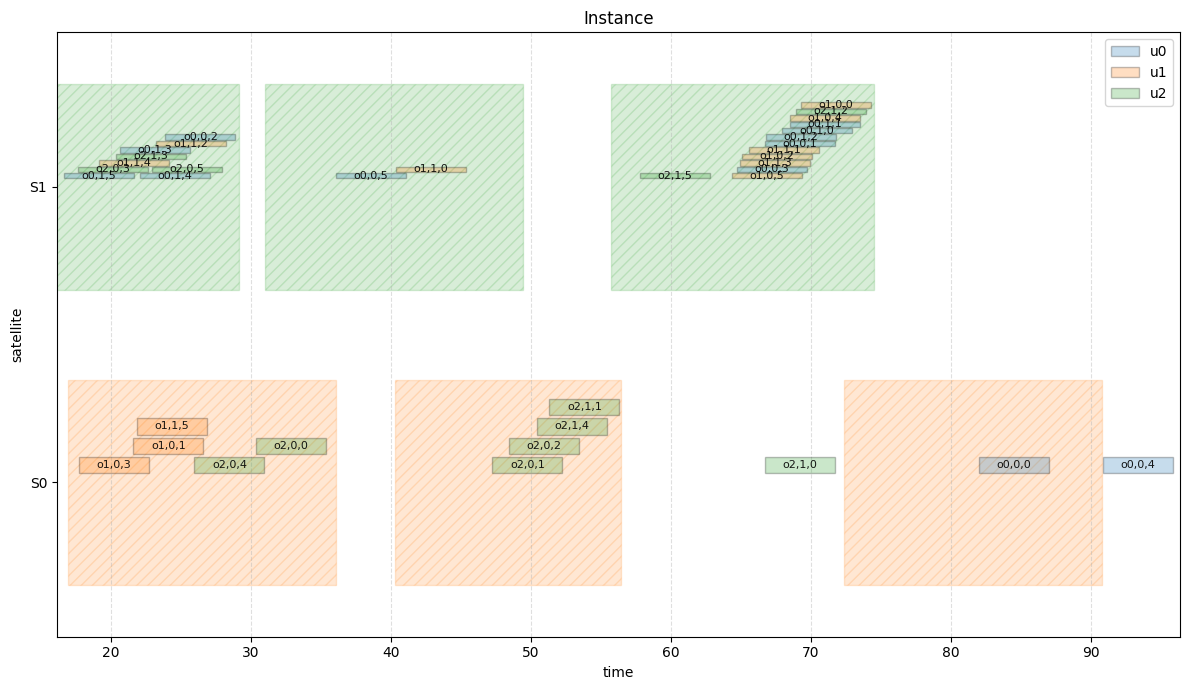

In [803]:
P2 = generate_EOSCSP(3, satellites, users, requests, observations)
print(format_eoscsp(P2, max_items=50))
plot_eoscsp_windows(
    P2,
    plan=None,
    title=f"Instance",
    show_exclusives=True,
    show_labels=True,
    show_plan_labels=True
)

In [804]:
def psi_solver(P, tau):
    """
    PSI (Algorithm 2) — utilise les helpers mutualisés.
    Retour: plan_global (list of (obs,start,end)), reward_total
    """
    U_ex = [u for u in P.U if is_exclusive(u)]
    u0 = next((u for u in P.U if not is_exclusive(u)), None)
    if u0 is None:
        u0 = type("CentralUser", (), {"e": []})()

    # 1) M_u0 ← ∅
    M_u0 = []

    # 2-4) solve(P[u]) + bids "parallèles"
    M_u = {}
    bids = {}
    sigma = {}
    for u in U_ex:
        _, _, M_u[u] = greedy_solver(P, tau=tau, u=u, restrict_to_exclusives=True)
        for r in P.R:
            b, sig = bid(P, r, u, M_u[u], tau)
            bids[(u, r)] = b
            sigma[(u, r)] = sig

    # 5-8) allocation avec ⊕ global
    R0 = {s: [] for s in P.S}
    served_global = set()

    for r in P.R:
        if r in served_global:
            continue

        w = None
        best_b = float("-inf")
        best_sig = None

        for u in U_ex:
            b = bids[(u, r)]
            sig = sigma[(u, r)]
            if sig is None:
                continue
            if b > best_b:
                best_b = b
                w = u
                best_sig = sig

        if w is None or best_sig is None or best_b == float("-inf"):
            continue

        o_win, _t_win = best_sig  # on ré-insère réellement dans la timeline globale
        t = first_slot(o_win, w, R0, tau)
        if t is None:
            continue

        M_u0.append((o_win, t, t + float(o_win.duration)))
        served_global.add(r)

    # 9) complétion centrale hors exclusives
    M_u0 = solve_central_with_fixed(P, M_u0, U_ex, u0, tau)

    M_u0.sort(key=lambda x: x[1])
    return M_u0, plan_reward(M_u0)

reward PSI: 120.37510252067096 nb obs: 4
=== ALLOCATED OBS (local ids) ===
o2,0,0 | start=30.39, end=35.39, sat=S0
o2,1,4 | start=50.47, end=55.47, sat=S0
o0,1,0 | start=67.92, end=72.92, sat=S1
o0,0,4 | start=90.89, end=95.89, sat=S0


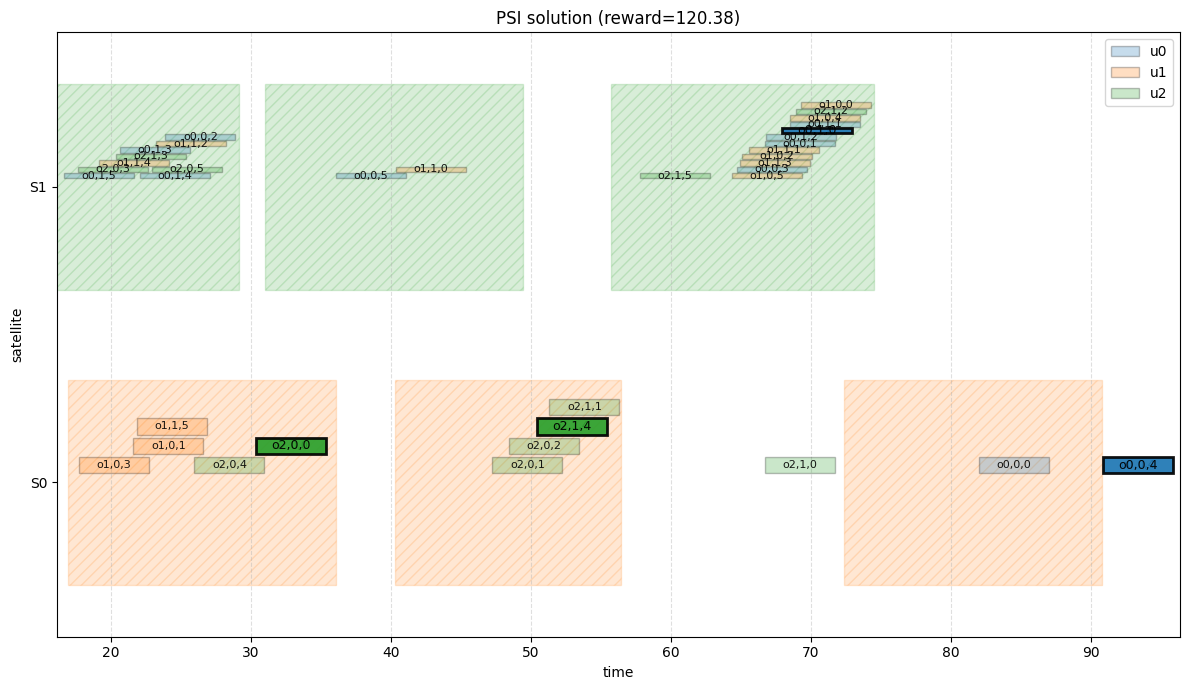

In [805]:
plan_psi, reward_psi = psi_solver(P2, tau=tau)
print("reward PSI:", reward_psi, "nb obs:", len(plan_psi))
print("=== ALLOCATED OBS (local ids) ===")
for obs, start, end in sorted(plan_psi, key=lambda x: x[1]):
    print(
        f"o{obs.u.u_id},{obs.r.r_local},{obs.o_local} | "
        f"start={start:.2f}, end={end:.2f}, "
        f"sat=S{obs.s.s_id}"
    )
plot_eoscsp_windows(
    P2,
    plan=plan_psi,
    title=f"PSI solution (reward={reward_psi:.2f})",
    show_exclusives=True,
    show_labels=True,
    show_plan_labels=True
)


In [806]:
def ssi_solver(P, tau):
    """
    SSI (Algorithm 3) — utilise les helpers.
    Retour: plan_global, reward_total
    """
    U_ex = [u for u in P.U if is_exclusive(u)]
    u0 = next((u for u in P.U if not is_exclusive(u)), None)
    if u0 is None:
        u0 = type("CentralUser", (), {"e": []})()

    # Items auctionnés = requêtes émises par u0
    R_emit = [r for r in P.R if getattr(r, "u", None) == u0]

    # solve(P[u])
    M_u = {u: greedy_solver(P, tau=tau, u=u, restrict_to_exclusives=True)[2] for u in U_ex}

    # allocations gagnées
    M_u0 = []
    served_fixed = set()

    for r in sorted(R_emit, key=lambda rr: getattr(rr, "p", 0)):
        if r in served_fixed:
            continue

        best_u = None
        best_b = float("-inf")
        best_sigma = None

        for u in U_ex:
            b, sig = bid(P, r, u, M_u[u], tau)
            if sig is None:
                continue
            if b > best_b:
                best_b = b
                best_u = u
                best_sigma = sig

        if best_u is None or best_sigma is None or best_b == float("-inf"):
            continue

        o_win, t_win = best_sigma
        alloc = (o_win, t_win, t_win + float(o_win.duration))

        M_u0.append(alloc)
        served_fixed.add(r)

        # ⊕ dans le plan du winner
        M_u[best_u].append(alloc)
        M_u[best_u].sort(key=lambda x: x[1])

    final_plan = solve_central_with_fixed(P, M_u0, U_ex, u0, tau)
    final_plan.sort(key=lambda x: x[1])
    return final_plan, plan_reward(final_plan)

reward SSI: 49.66998852116734 nb obs: 2
=== ALLOCATED OBS (local ids) ===
o2,1,0 | start=66.74, end=71.74, sat=S0
o0,0,1 | start=66.75, end=71.75, sat=S1


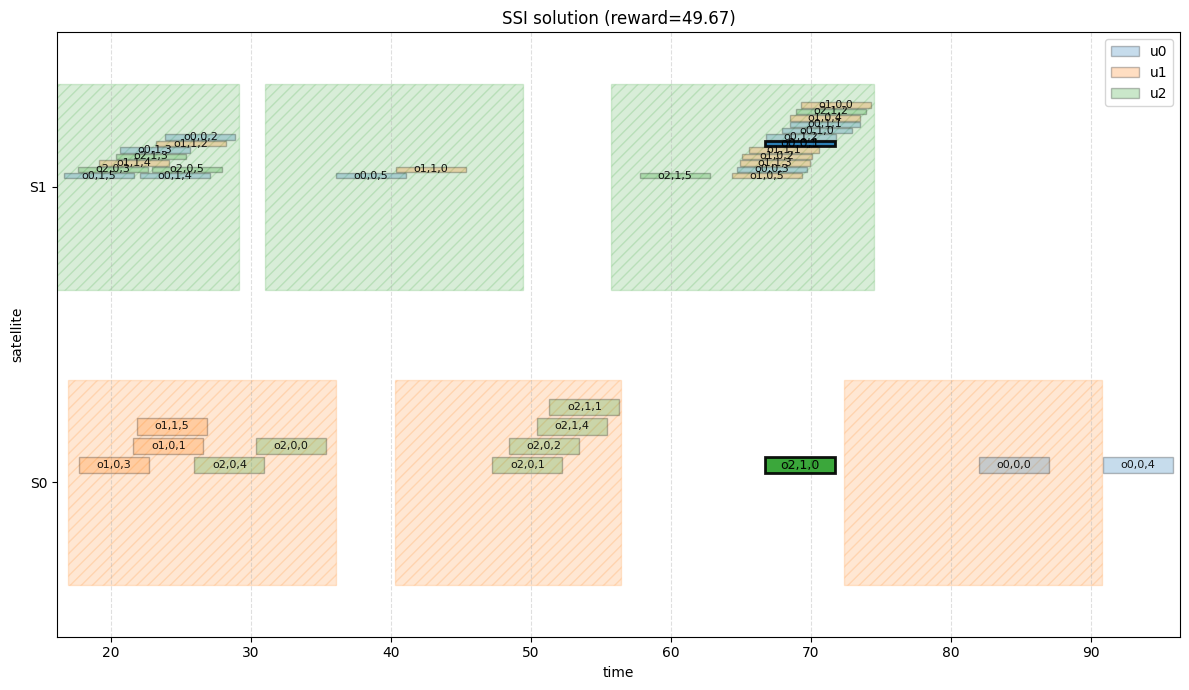

In [807]:
plan_ssi, reward_ssi = ssi_solver(P2, tau=tau)
print("reward SSI:", reward_ssi, "nb obs:", len(plan_ssi))
print("=== ALLOCATED OBS (local ids) ===")
for obs, start, end in sorted(plan_ssi, key=lambda x: x[1]):
    print(
        f"o{obs.u.u_id},{obs.r.r_local},{obs.o_local} | "
        f"start={start:.2f}, end={end:.2f}, "
        f"sat=S{obs.s.s_id}"
    )
plot_eoscsp_windows(
    P2,
    plan=plan_ssi,
    title=f"SSI solution (reward={reward_ssi:.2f})",
    show_exclusives=True,
    show_labels=True,
    show_plan_labels=True
)

In [808]:
def ssi_regret_solver(P, tau, eps=1e-12):
    """
    SSI auctions with Regret Clearing (Koenig et al.) adapté en MAXIMISATION.

    - bid() inchangé (même que SSI standard): bid(P,r,u,M_u_plan,tau) -> (gain, sigma=(o,t))
    - winner determination:
        regret(r) = best_gain(r) - second_best_gain(r)
        choisir r* avec regret max, puis l'allouer au bidder best_gain.

    Retour: (plan_global, reward_total)
    """

    # ---------- sets ----------
    U_ex = [u for u in P.U if is_exclusive(u)]
    u0 = next((u for u in P.U if not is_exclusive(u)), None)
    if u0 is None:
        u0 = type("CentralUser", (), {"e": []})()

    # Requests "émises" par u0
    R_emit = [r for r in P.R if getattr(r, "u", None) == u0]
    remaining = list(R_emit)

    # ---------- init local plans solve(P[u]) (dans exclusives) ----------
    # greedy_solver retourne (M_dict, reward, plan)
    M_u = {
        u: greedy_solver(P, tau=tau, u=u, restrict_to_exclusives=True)[2]
        for u in U_ex
    }

    # allocations fixes gagnées
    M_u0 = []

    # ---------- rounds ----------
    while remaining:

        best_info = {}   # r -> (best_gain, best_u, best_sigma=(o,t))
        second_best = {} # r -> second_best_gain (ou 0.0 si un seul bidder possible)

        any_feasible = False

        for r in remaining:
            per_u = []
            for u in U_ex:
                g, sig = bid(P, r, u, M_u[u], tau)   # <-- bid SSI standard
                if sig is None or g == float("-inf"):
                    continue
                per_u.append((float(g), u, sig))

            if not per_u:
                best_info[r] = (float("-inf"), None, None)
                second_best[r] = float("-inf")
                continue

            any_feasible = True
            per_u.sort(key=lambda x: x[0], reverse=True)

            g1, u1, sig1 = per_u[0]
            g2 = per_u[1][0] if len(per_u) >= 2 else 0.0  # si seul bidder: second=0

            best_info[r] = (g1, u1, sig1)
            second_best[r] = g2

        if not any_feasible:
            break  # plus aucun bid possible

        # choisir r* max regret
        r_star = None
        best_regret = float("-inf")
        best_g1 = float("-inf")

        for r in remaining:
            g1, u1, sig1 = best_info[r]
            if sig1 is None or g1 == float("-inf"):
                continue

            g2 = second_best[r]
            regret = g1 - g2

            # tie-break: meilleur g1
            if (regret > best_regret + eps) or (abs(regret - best_regret) <= eps and g1 > best_g1 + eps):
                best_regret = regret
                best_g1 = g1
                r_star = r

        if r_star is None:
            break

        # commit allocation
        g_win, u_win, (o_win, t_win) = best_info[r_star]
        alloc = (o_win, float(t_win), float(t_win) + float(o_win.duration))

        M_u0.append(alloc)
        M_u[u_win].append(alloc)
        M_u[u_win].sort(key=lambda x: x[1])

        remaining.remove(r_star)

    # completion centrale hors exclusives
    final_plan = solve_central_with_fixed(P, M_u0, U_ex, u0, tau)
    total_reward = plan_reward(final_plan)
    return final_plan, total_reward

reward SSI: 88.41535508559058 nb obs: 3
=== ALLOCATED OBS (local ids) ===
o0,0,2 | start=23.91, end=28.91, sat=S1
o2,1,0 | start=66.74, end=71.74, sat=S0
o0,1,0 | start=67.92, end=72.92, sat=S1


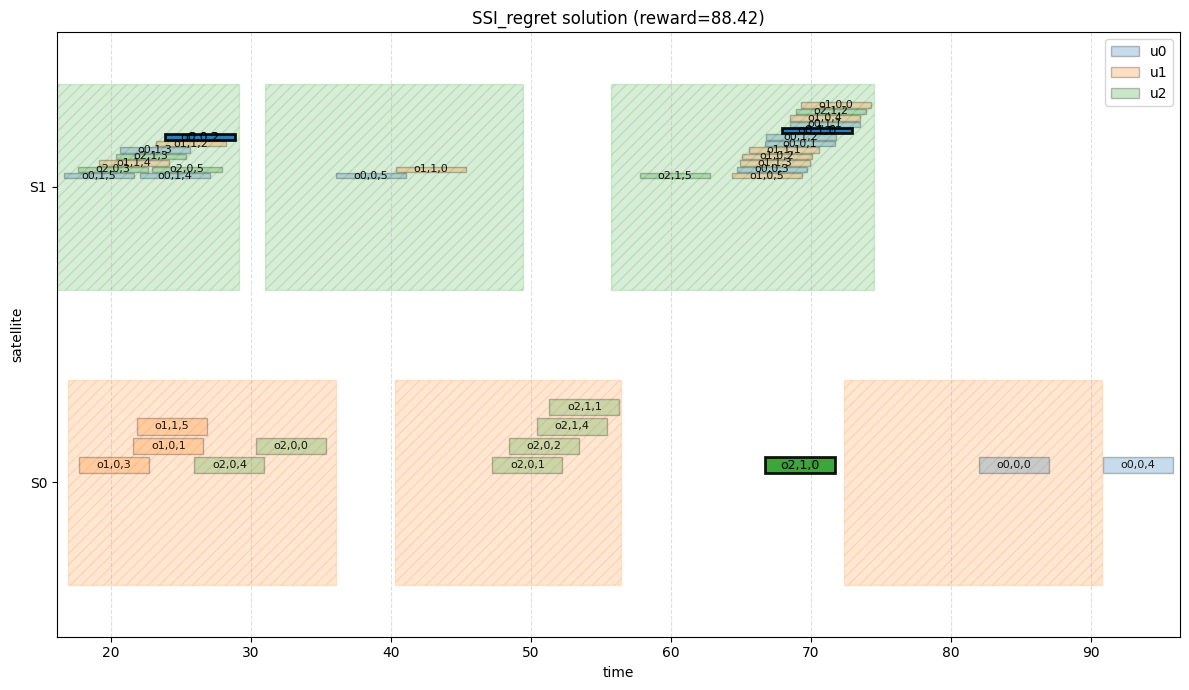

In [809]:
plan_ssi_regret, reward_ssi_regret = ssi_regret_solver(P2, tau=tau)
print("reward SSI:", reward_ssi_regret, "nb obs:", len(plan_ssi_regret))
print("=== ALLOCATED OBS (local ids) ===")
for obs, start, end in sorted(plan_ssi_regret, key=lambda x: x[1]):
    print(
        f"o{obs.u.u_id},{obs.r.r_local},{obs.o_local} | "
        f"start={start:.2f}, end={end:.2f}, "
        f"sat=S{obs.s.s_id}"
    )
plot_eoscsp_windows(
    P2,
    plan=plan_ssi_regret,
    title=f"SSI_regret solution (reward={reward_ssi_regret:.2f})",
    show_exclusives=True,
    show_labels=True,
    show_plan_labels=True
)

In [810]:
horizon = 200.0

# moins de satellites => plus de conflits
satellites = generate_satellites(2, horizon, 50, 80)

# 1 u0 non-exclusif
users_no_exclusifs = generate_users(2)

# 2 exclusifs
users_exclusifs = generate_users_exclusifs(len(users_no_exclusifs), satellites, 3)

users = users_no_exclusifs.union(users_exclusifs)

# BEAUCOUP plus de requêtes (surtout u0) => plus de divergence PSI/SSI
requests = generate_requests(users, 8, horizon, 8.0, 18.0, 10.0, 60.0)

# plus d'opportunités par requête => plus de choix => plus de divergence
observations = generate_observations(satellites, users, requests, 6, 10.0, 25.0)

eoscsp_diff = generate_EOSCSP(99, satellites, users, requests, observations)

plan_psi, rew_psi = psi_solver(eoscsp_diff, tau=tau)
plan_ssi, rew_ssi = ssi_solver(eoscsp_diff, tau=tau)
plan_ssi_regret, rew_ssi_regret = ssi_regret_solver(eoscsp_diff, tau=tau)

print("PSI reward:", rew_psi, "obs:", len(plan_psi))
print("SSI reward:", rew_ssi, "obs:", len(plan_ssi))
print("SSI_regret reward:", rew_ssi_regret, "obs:", len(plan_ssi_regret))


PSI reward: 716.7814392236503 obs: 19
SSI reward: 705.9346117880954 obs: 18
SSI_regret reward: 705.9346117880953 obs: 18


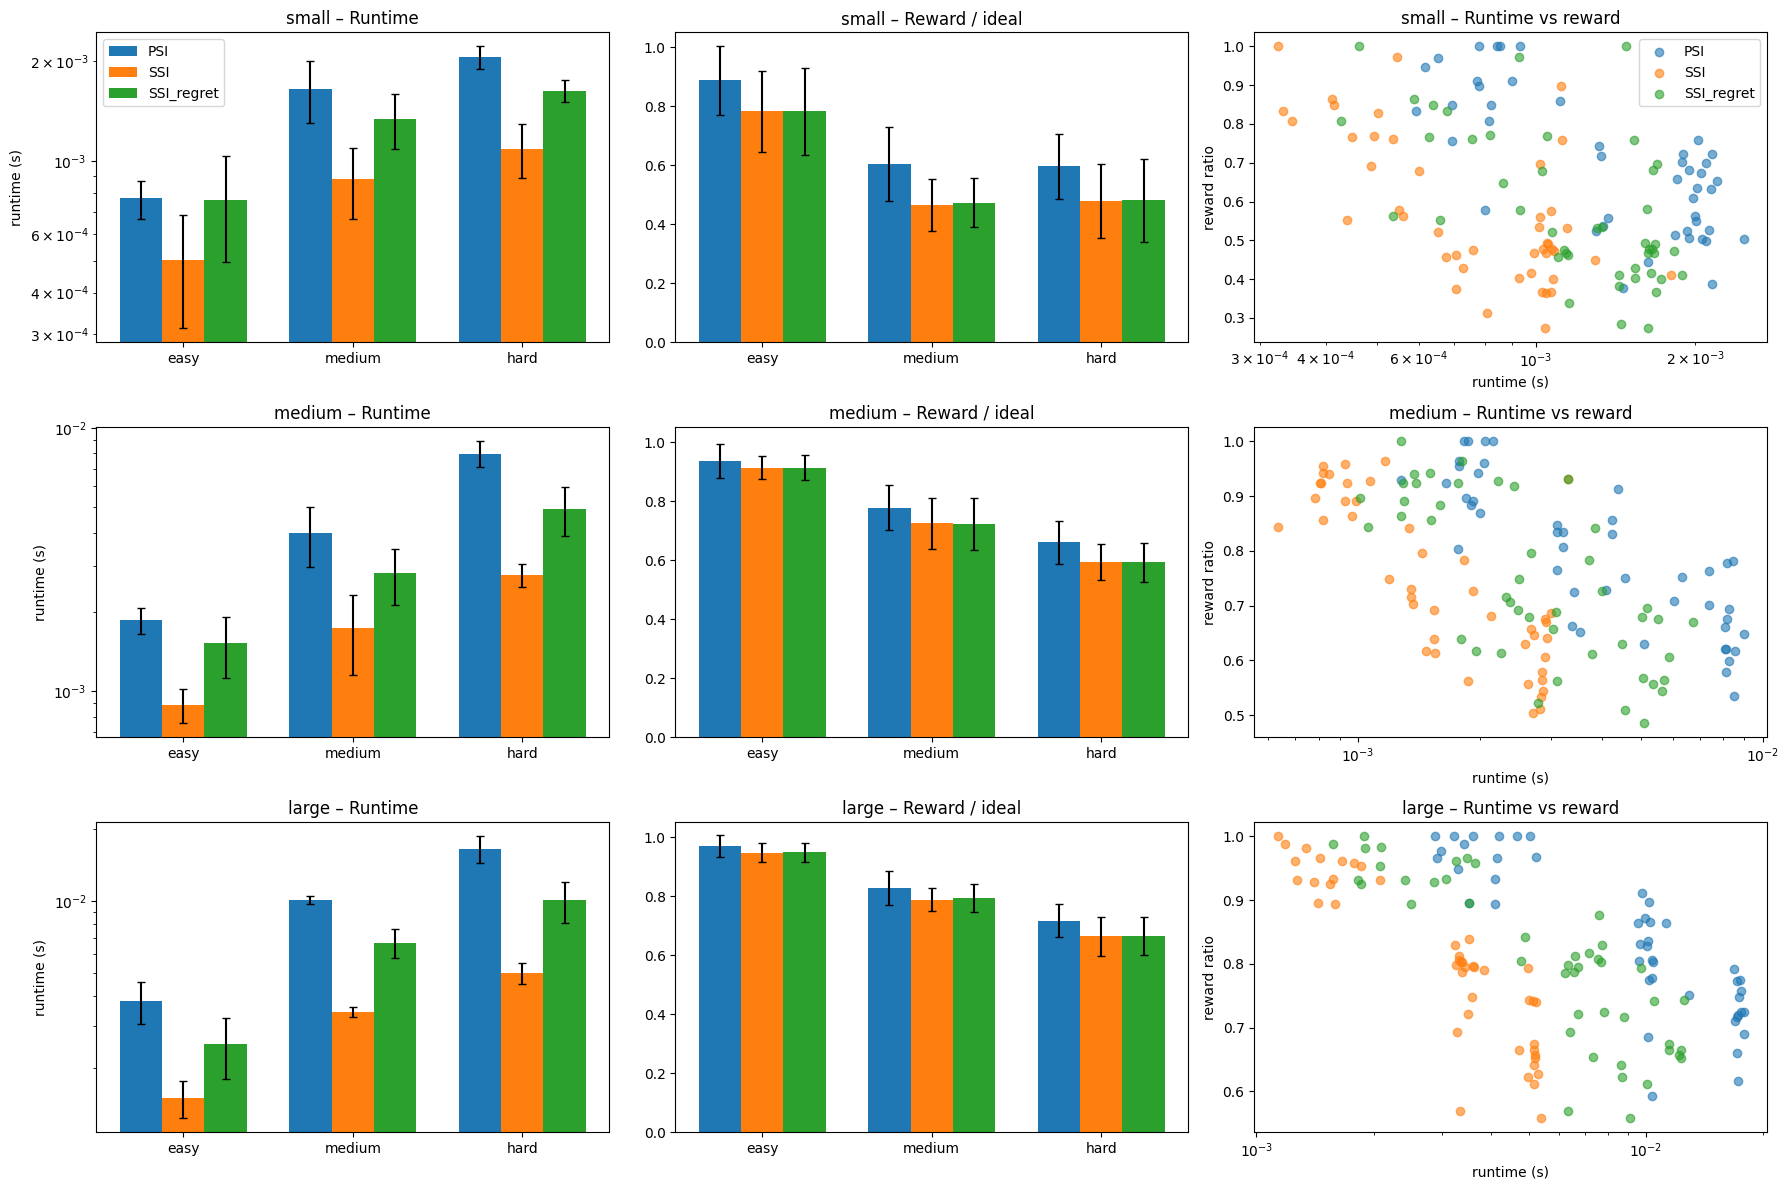

In [811]:
N_RUNS = 15
HORIZON = 100.0

ALGOS = {
    "PSI": psi_solver,
    "SSI": ssi_solver,
    "SSI_regret": ssi_regret_solver, 
}

SIZES = {
    "small":  dict(n_sats=3, n_non_ex=1, n_ex=3, req_per_user=4, obs_per_req=5),
    "medium": dict(n_sats=5, n_non_ex=2, n_ex=5, req_per_user=6, obs_per_req=6),
    "large":  dict(n_sats=7, n_non_ex=3, n_ex=7, req_per_user=8, obs_per_req=7),
}

DIFFICULTIES = {
    "easy": dict(
        dur_min=4.0, dur_max=10.0,     # durées plus longues
        slack_min=14.0, slack_max=28.0,# fenêtres moins larges
        ex_windows=2,                  # plus d'exclusives
        tau_kind="mild"
    ),
    "medium": dict(
        dur_min=6.0, dur_max=16.0,
        slack_min=8.0, slack_max=18.0,
        ex_windows=3,
        tau_kind="hard"                # transitions plus pénalisantes
    ),
    "hard": dict(
        dur_min=10.0, dur_max=24.0,
        slack_min=5.0, slack_max=10.0, # fenêtres très étroites
        ex_windows=4,                  
        tau_kind="hard"
    ),
}

def tau_from_kind(kind):
    if kind == "hard":
        return lambda a, b: 2.0
    return lambda a, b: 1.0

def ideal_upper_bound(P):
    """
    Upper bound "théorique": somme_{r} max_{o in theta(r)} reward(o)
    Ignore contraintes -> borne sup.
    """
    best = {}
    for o in P.O:
        r = getattr(o, "r", None)
        if r is None:
            continue
        rew = float(getattr(o, "reward", getattr(o, "rho", 0.0)) or 0.0)
        best[r] = max(best.get(r, 0.0), rew)
    return float(sum(best.values())) if best else 0.0

def generate_instance(size_cfg, diff_cfg, horizon=HORIZON):
    # satellites
    satellites = generate_satellites(size_cfg["n_sats"], horizon, 100, 200)

    # users
    users_no_ex = generate_users(size_cfg["n_non_ex"])
    users_ex = generate_users_exclusifs(len(users_no_ex), satellites, diff_cfg["ex_windows"])
    users = users_no_ex.union(users_ex)

    # requests
    requests = generate_requests(
        users,
        size_cfg["req_per_user"],
        horizon,
        diff_cfg["dur_min"],
        diff_cfg["dur_max"],
        5.0,
        50.0,
    )

    # observations
    observations = generate_observations(
        satellites,
        users,
        requests,
        size_cfg["obs_per_req"],
        diff_cfg["slack_min"],
        diff_cfg["slack_max"],
    )

    P = generate_EOSCSP(0, satellites, users, requests, observations)
    return P

def run_one_algo(algo_fn, P, tau):
    t0 = time.perf_counter()
    plan, reward = algo_fn(P, tau=tau)
    t1 = time.perf_counter()
    return (t1 - t0), float(reward), plan

# ----------------------------
# RUN BENCH
# ----------------------------
# stockage brut : dict[size][difficulty][algo] -> list of metrics dict
raw = {size: {diff: {a: [] for a in ALGOS} for diff in DIFFICULTIES} for size in SIZES}

for size_name, size_cfg in SIZES.items():
    for diff_name, diff_cfg in DIFFICULTIES.items():
        tau = tau_from_kind(diff_cfg["tau_kind"])

        for run in range(N_RUNS):
            P = generate_instance(size_cfg, diff_cfg, horizon=HORIZON)
            ideal = ideal_upper_bound(P)
            if ideal <= 1e-12:
                ideal = 1e-12

            for algo_name, algo_fn in ALGOS.items():
                runtime, reward, plan = run_one_algo(algo_fn, P, tau)

                reward_ratio = reward / ideal
                x_over_y = runtime / max(reward_ratio, 1e-9)  # runtime / reward_ratio

                raw[size_name][diff_name][algo_name].append({
                    "runtime": runtime,
                    "reward": reward,
                    "ideal": ideal,
                    "reward_ratio": reward_ratio,
                    "x_over_y": x_over_y,
                    "n_obs": len(plan),
                })

# ----------------------------
# AGG STATS (mean/std)
# ----------------------------
def mean_std(values):
    arr = np.array(values, dtype=float)
    if arr.size == 0:
        return 0.0, 0.0
    return float(arr.mean()), float(arr.std(ddof=1)) if arr.size > 1 else 0.0

# stats[size][diff][algo] -> dict metrics mean/std
stats = {size: {diff: {} for diff in DIFFICULTIES} for size in SIZES}

for size in SIZES:
    for diff in DIFFICULTIES:
        for algo in ALGOS:
            lst = raw[size][diff][algo]
            stats[size][diff][algo] = {
                "runtime_mean": mean_std([x["runtime"] for x in lst])[0],
                "runtime_std":  mean_std([x["runtime"] for x in lst])[1],
                "ratio_mean":   mean_std([x["reward_ratio"] for x in lst])[0],
                "ratio_std":    mean_std([x["reward_ratio"] for x in lst])[1],
                "x_over_y_mean":mean_std([x["x_over_y"] for x in lst])[0],
                "x_over_y_std": mean_std([x["x_over_y"] for x in lst])[1],
                "reward_mean":  mean_std([x["reward"] for x in lst])[0],
                "reward_std":   mean_std([x["reward"] for x in lst])[1],
                "nobs_mean":    mean_std([x["n_obs"] for x in lst])[0],
            }

# ----------------------------
# PRINT SUMMARY TABLE (text)
# ----------------------------
# for size in SIZES:
#     print("\n==============================")
#     print("SIZE:", size)
#     print("==============================")
#     for diff in DIFFICULTIES:
#         print(f"\n  Difficulty: {diff}")
#         for algo in ALGOS:
#             s = stats[size][diff][algo]
#             print(
#                 f"    {algo:10s} | "
#                 f"runtime={s['runtime_mean']:.4f}±{s['runtime_std']:.4f}s | "
#                 f"ratio={s['ratio_mean']:.3f}±{s['ratio_std']:.3f} | "
#                 f"x/y={s['x_over_y_mean']:.4f}±{s['x_over_y_std']:.4f} | "
#                 f"nobs~{s['nobs_mean']:.2f}"
#             )

def plot_all_sizes_grid():
    sizes = list(SIZES.keys())          # rows
    diffs = list(DIFFICULTIES.keys())
    algos = list(ALGOS.keys())

    fig, axes = plt.subplots(
        nrows=len(sizes),
        ncols=3,
        figsize=(18, 12),
        sharex=False
    )

    for row, size in enumerate(sizes):
        x = np.arange(len(diffs))
        width = 0.25
        offsets = np.linspace(-width, width, len(algos))

        # ------------------
        # 1) Runtime (log)
        # ------------------
        ax = axes[row, 0]
        for i, algo in enumerate(algos):
            means = [stats[size][d][algo]["runtime_mean"] for d in diffs]
            stds  = [stats[size][d][algo]["runtime_std"] for d in diffs]
            ax.bar(x + offsets[i], means, width=width, yerr=stds, capsize=3, label=algo)

        ax.set_yscale("log")
        ax.set_xticks(x)
        ax.set_xticklabels(diffs)
        ax.set_title(f"{size} – Runtime")
        ax.set_ylabel("runtime (s)")

        # ------------------
        # 2) Reward ratio
        # ------------------
        ax = axes[row, 1]
        for i, algo in enumerate(algos):
            means = [stats[size][d][algo]["ratio_mean"] for d in diffs]
            stds  = [stats[size][d][algo]["ratio_std"] for d in diffs]
            ax.bar(x + offsets[i], means, width=width, yerr=stds, capsize=3)

        ax.set_xticks(x)
        ax.set_xticklabels(diffs)
        ax.set_ylim(0, 1.05)
        ax.set_title(f"{size} – Reward / ideal")

        # ------------------
        # 3) Scatter runtime vs reward
        # ------------------
        ax = axes[row, 2]
        for algo in algos:
            xs, ys = [], []
            for diff in diffs:
                for rec in raw[size][diff][algo]:
                    xs.append(rec["runtime"])
                    ys.append(rec["reward_ratio"])
            ax.scatter(xs, ys, alpha=0.6, label=algo)

        ax.set_xscale("log")
        ax.set_title(f"{size} – Runtime vs reward")
        ax.set_xlabel("runtime (s)")
        ax.set_ylabel("reward ratio")

        # legend seulement sur la première ligne
        if row == 0:
            axes[row, 0].legend()
            axes[row, 2].legend()

    plt.tight_layout()
    plt.show()
plot_all_sizes_grid()    

## 5 - Conclusion